# STEP6. 수익률곡선 다요인 모형 분석

## 분석 질문

산업별 주가는 금리 전반의 수준, 장단기 기울기, 중기 구간의 곡률, 신용위험 중
무엇에 더 민감하게 반응하는가?

- **관련 가설** — H1(금리충격 원천에 따른 이질성)
- **선행 단계** — Baseline(STEP4·STEP5)에서 국고채 3년 기준 산업 간 금리베타 차이를 확인했다.

## 입력

| 구분 | 경로 |
|---|---|
| 산업·KOSPI 패널 | `data/processed/industry_rate_panel_daily.csv` |
| 국고채 1·3·5·10년 | `data/raw/rates/treasury_yield_curve_1_3_5_10y.csv` |
| 회사채 AA− 3년 | `data/raw/rates/corporate_bond_aa_minus_3y.csv` |

## 출력

**데이터**

- `data/processed/industry_rate_panel_extended.csv`

**Table** — `results/H1_yield_curve/tables/`

| 파일 | 담당 |
|---|---|
| `maturity_beta_comparison.csv` | B-1 |
| `yield_curve_factor_betas.csv` | B-1 |
| `credit_spread_betas.csv` | B-2 |
| `factor_correlation_vif.csv` | B-2 |
| `industry_difference_test.csv` | 사후 |
| `exploratory_yield_pca.csv` | 사후 |
| `exploratory_model_parsimony.csv` | 사후 |
| `exploratory_joint_ftest.csv` | 사후 |
| `exploratory_two_factor_betas.csv` | 사후 |
| `exploratory_orthogonalized_betas.csv` | 사후 |
| `exploratory_hac_sensitivity.csv` | 사후 |

**Figure** — `results/H1_yield_curve/figures/`

| 파일 | 담당 |
|---|---|
| `01_maturity_beta_comparison_heatmap.png` | B-1 |
| `02_yield_curve_factor_beta_heatmap.png` | B-1 |
| `03_{level,slope,curvature}_coefficient_plot.png` | B-1 |
| `04_yield_curve_factor_ci.png` | B-2 |
| `05_joint_ftest.png` ~ `10_hac_sensitivity.png` | 사후 |

**Summary**

- `results/H1_yield_curve/summary.md` — 텍스트 요약
- `results/H1_yield_curve/06_summary_final.html` — 표·그림 포함 공유용 리포트

## 구성

| 파트 | 내용 | 성격 |
|---|---|---|
| PART A | 3년·10년·장단기차 개별 회귀 비교 | 확증 |
| PART B | Nelson–Siegel Level·Slope·Curvature 동시모형 | 확증 |
| PART C | Credit Spread 강건성 검증 | 확증 |
| PART D | 다중공선성 진단과 추가 검정 | **사후** |

> PART D는 PART A~C 결과를 본 뒤 설계한 사후 분석이다.
> 미리 계획한 검정과 같은 무게를 갖지 않으며, 산출물은 `exploratory_` 접두로 구분한다.


## 전체 수행 흐름

**PART A·B — 수익률곡선 요인 (B-1)**

1. 라이브러리와 경로 설정
2. 산업 패널 불러오기
3. 국고채 1·3·5·10년 정리
4. 산업 패널과 금리자료 병합
5. 3년·10년·장단기차 개별 회귀
6. 만기별 비교표와 그림
7. Nelson–Siegel 공통 λ 선택
8. 날짜별 Level·Slope·Curvature와 변화량
9. 세 요인 동시모형 추정
10. 계수·SE·t·p·신뢰구간 표
11. 요인 민감도 heatmap과 계수 플롯

**PART C — Credit Spread (B-2)**

12. Credit Spread 단독모형
13. Credit Spread 포함 확장모형
14. BH 보정과 결과표 저장
15. 요인 상관행렬과 VIF
16. 4요인 계수 신뢰구간 그림
17. 강건성 판정
18. 요약 문서

**PART D — 사후 진단**

- D-0 주성분분석
- D-1 동시검정
- D-2 2요인 축소
- D-3 직교화
- D-4 산업 간 계수 동일성 검정
- D-5 모형 비교
- D-6 HAC 시차 민감도



## 1단계. 라이브러리와 프로젝트 경로 설정

In [1]:
# --- 저장소 루트 부트스트랩 (모든 노트북 공통, 수정 금지) ---
# 저장소 루트에서 `pip install -e .` 를 한 번 실행했다면 아래 탐색은 건너뛴다.
import sys
from pathlib import Path

_anchors = []
if "__vsc_ipynb_file__" in globals():          # VS Code Notebook
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):                        # IPython 커널 시작 폴더 (Jupyter/Lab/Colab)
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())           # 최후 수단

# config.py 와 requirements.txt 를 '둘 다' 가진 폴더만 저장소 루트로 인정한다.
# 마커를 하나만 보면 다른 폴더의 동명 config.py 를 잘못 집을 수 있다.
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
# 이미 sys.path에 있더라도 맨 앞으로 올린다. cwd(예: 바탕화면)가 앞에 있으면
# 같은 이름의 다른 config.py 가 먼저 잡히기 때문이다.
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))

import config

if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(
        f"의도하지 않은 config.py 가 import 되었습니다: {config.__file__}\n"
        f"저장소 루트({_root})에서 `pip install -e .` 를 실행하세요."
    )
# --- 부트스트랩 끝 ---

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from scipy.optimize import minimize_scalar

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# 한글 폰트. 공통 설정은 config.setup_korean_font() 한 곳에서 관리한다
# (docs/STYLE_GUIDE.md, config.py 5-c절).
# ---------------------------------------------------------------
config.setup_korean_font()

# ---------------------------------------------------------------
# 경로는 전부 config에서 가져온다.
# 로컬 별칭(PANEL_PATH = ... 같은 재정의)을 만들지 않는다. 별칭을 만들면 셀을
# 순서대로 실행하지 않았을 때 NameError가 나고, config와 값이 어긋날 수 있다.
# ---------------------------------------------------------------
if not config.RAW_YIELD_CURVE_FILE.exists():
    raise FileNotFoundError(
        f"국고채 1·3·5·10년 원본을 찾지 못했습니다: {config.RAW_YIELD_CURVE_FILE}\n"
        "config.describe() 로 탐색 결과를 확인하세요."
    )

if not config.PANEL_PATH.exists():
    raise FileNotFoundError(
        f"산업 패널을 찾지 못했습니다: {config.PANEL_PATH}\n"
        "01_data_preparation → 02_variable_generation 을 먼저 실행하세요."
    )

config.describe()


그래프 폰트: Noto Sans CJK JP
PROJECT_ROOT : /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern
DATA_DIR     : data  (exists=True)

[raw 파일]
  [OK     ] RAW_YIELD_FILE: data/raw/rates/treasury_yield_3y_10y.csv
  [OK     ] RAW_YIELD_CURVE_FILE: data/raw/rates/treasury_yield_curve_1_3_5_10y.csv
  [OK     ] RAW_CREDIT_SPREAD_FILE: data/raw/rates/corporate_bond_aa_minus_3y.csv

[가공 데이터]
  [OK     ] PANEL_PATH: data/processed/industry_rate_panel_daily.csv
  [OK     ] EXTENDED_PANEL_PATH: data/processed/industry_rate_panel_extended.csv

[산업 원본 폴더]


  KOSPI 화학     data/raw/industry/chemicals              (5 files)
  KOSPI 건설업    data/raw/industry/construction           (5 files)
  KOSPI 전기전자   data/raw/industry/electronics            (5 files)
  KOSPI 금융업    data/raw/industry/financials             (5 files)
  KOSPI 금속     data/raw/industry/metal                  (5 files)
  KOSPI 의약품    data/raw/industry/pharma                 (5 files)
  KOSPI 운수장비   data/raw/industry/transport_equipment    (5 files)
  KOSPI        data/raw/market/kospi_index              (5 files)



## 2단계. 산업 패널데이터 불러오기

### 왜 확인이 필요한가?

이번 분석의 종속변수는 `industry_return`, 시장 통제변수는 `kospi_return`이다.  
또한 기존 만기별 비교를 위해 `d_y3`, `d_y10`, `d_term_spread`가 있는지도 확인한다.


In [2]:
panel = pd.read_csv(config.PANEL_PATH, encoding="utf-8-sig")
panel["date"] = pd.to_datetime(panel["date"], errors="coerce")

required_panel_cols = [
    "date",
    "industry",
    "industry_return",
    "kospi_return",
    "d_y3",
    "d_y10",
    "d_term_spread",
]

missing_cols = [c for c in required_panel_cols if c not in panel.columns]

if missing_cols:
    raise ValueError(
        "산업 패널데이터에 필요한 컬럼이 없습니다: "
        + ", ".join(missing_cols)
    )

panel = panel.sort_values(["date", "industry"]).reset_index(drop=True)

print("패널 크기:", panel.shape)
print("분석 기간:", panel["date"].min(), "~", panel["date"].max())
print("산업 수:", panel["industry"].nunique())
print("산업 목록:", sorted(panel["industry"].dropna().unique()))
display(panel.head())

패널 크기: (17164, 12)
분석 기간: 2016-01-04 00:00:00 ~ 2025-12-30 00:00:00
산업 수: 7
산업 목록: ['건설업', '금융업', '운수장비', '의약품', '전기전자', '철강금속', '화학']


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,term_spread,d_term_spread
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,0.405,NaN



## 3단계. 국고채 금리자료 불러오기

### 왜 형태를 바꿔야 하나?

ECOS 원본은 만기가 행에 있고 날짜가 열에 있는 형태다.  
이를 날짜별로 1년·3년·5년·10년 금리가 한 행에 들어가도록 바꿔야 Nelson–Siegel 모형을 적용할 수 있다.


In [3]:
# 국고채 1·3·5·10년 원본을 읽는다. 경로·확장자는 config가 관리한다.
yield_raw = pd.read_csv(config.RAW_YIELD_CURVE_FILE, encoding="utf-8-sig")

print("원본 금리자료:", config.RAW_YIELD_CURVE_FILE.name, yield_raw.shape)
display(yield_raw.iloc[:, :12])


원본 금리자료: treasury_yield_curve_1_3_5_10y.csv (4, 2466)


,통계표,계정항목,단위,변환,2016/01/04,2016/01/05,2016/01/06,2016/01/07,2016/01/08,2016/01/11,2016/01/12,2016/01/13
0,1.3.2.1. 시장금리(일별),국고채(1년),연%,원자료,1.605,1.602,1.601,1.598,1.608,1.590,1.588,1.587
1,1.3.2.1. 시장금리(일별),국고채(3년),연%,원자료,1.634,1.643,1.639,1.639,1.665,1.635,1.638,1.633
2,1.3.2.1. 시장금리(일별),국고채(5년),연%,원자료,1.778,1.792,1.788,1.780,1.813,1.775,1.784,1.780
3,1.3.2.1. 시장금리(일별),국고채(10년),연%,원자료,2.039,2.057,2.035,2.015,2.057,2.025,2.036,2.025


In [4]:
if "계정항목" not in yield_raw.columns:
    raise ValueError("금리자료에서 '계정항목' 컬럼을 찾지 못했습니다.")

maturity_map = {
    "국고채(1년)": "y1",
    "국고채(3년)": "y3_new",
    "국고채(5년)": "y5",
    "국고채(10년)": "y10_new",
}

yield_selected = yield_raw[
    yield_raw["계정항목"].isin(maturity_map.keys())
].copy()

if len(yield_selected) != 4:
    raise ValueError("국고채 1년·3년·5년·10년 행을 모두 찾지 못했습니다.")

yield_selected["maturity_name"] = yield_selected["계정항목"].map(maturity_map)

metadata_cols = [
    col for col in ["통계표", "계정항목", "단위", "변환"]
    if col in yield_selected.columns
]

date_cols = [
    col for col in yield_selected.columns
    if col not in metadata_cols + ["maturity_name"]
]

yield_long = yield_selected.melt(
    id_vars=["maturity_name"],
    value_vars=date_cols,
    var_name="date",
    value_name="yield",
)

yield_long["date"] = pd.to_datetime(yield_long["date"], errors="coerce")
yield_long["yield"] = pd.to_numeric(yield_long["yield"], errors="coerce")

yield_wide = (
    yield_long
    .pivot(index="date", columns="maturity_name", values="yield")
    .reset_index()
    .sort_values("date")
    .dropna()
    .reset_index(drop=True)
)

yield_wide.columns.name = None
yield_wide = yield_wide[["date", "y1", "y3_new", "y5", "y10_new"]]

yield_wide["term_spread_new"] = yield_wide["y10_new"] - yield_wide["y1"]

for col in ["y1", "y3_new", "y5", "y10_new", "term_spread_new"]:
    yield_wide[f"d_{col}"] = yield_wide[col].diff()

print("정리된 금리자료 크기:", yield_wide.shape)
print("금리 기간:", yield_wide["date"].min(), "~", yield_wide["date"].max())
display(yield_wide.head())

정리된 금리자료 크기: (2462, 11)
금리 기간: 2016-01-04 00:00:00 ~ 2025-12-31 00:00:00


,date,y1,y3_new,y5,y10_new,term_spread_new,d_y1,d_y3_new,d_y5,d_y10_new,d_term_spread_new
0,2016-01-04,1.605,1.634,1.778,2.039,0.434,NaN,NaN,NaN,NaN,NaN
1,2016-01-05,1.602,1.643,1.792,2.057,0.455,-0.003,0.009,0.014,0.018,0.021
2,2016-01-06,1.601,1.639,1.788,2.035,0.434,-0.001,-0.004,-0.004,-0.022,-0.021
3,2016-01-07,1.598,1.639,1.780,2.015,0.417,-0.003,0.000,-0.008,-0.020,-0.017
4,2016-01-08,1.608,1.665,1.813,2.057,0.449,0.010,0.026,0.033,0.042,0.032


## 3-1단계. 회사채 AA− 결합과 Credit Spread 생성 (B-2)

### 무엇을 만드나?

$$
CreditSpread_t = CorpBond^{AA-}_{3Y,t} - y_{3Y,t}
$$

회사채(3년, AA−)에서 같은 만기의 국고채 3년을 뺀 값이다.
같은 만기끼리 빼기 때문에 만기 프리미엄이 상쇄되고 **신용위험 프리미엄**만 남는다.
두 금리 모두 단위가 연 %이므로 스프레드는 %p, 일별 변화분 `d_credit_spread`도 %p다.
`d_ns_level` 등 다른 요인과 단위가 같아 계수 크기를 직접 비교할 수 있다.

### 왜 국고채 3년을 `y3_new`로 쓰나?

패널에 이미 있는 `d_y3`는 Baseline이 쓰는 별도 원본(`RAW_YIELD_FILE`)에서 왔다.
스프레드는 두 금리의 **차이**라서 출처가 섞이면 그 차이가 그대로 오차로 남는다.
따라서 국고채 3년은 이번 곡선 원본에서 만든 `yield_wide["y3_new"]`로 통일한다.

### 왜 `how="left"` 병합인가?

`inner` 병합이나 추가 `dropna()`를 쓰면 `yield_wide`의 행 수가 줄 수 있다.
그러면 7단계의 공통 λ 최적화 입력이 바뀌고, Nelson–Siegel 요인과
**B-1이 이미 만든 결과 전체가 조용히 달라진다.**
아래 `assert`가 그 사고를 막는다.


In [5]:
# Credit Spread = 회사채(3년, AA-) - 국고채 3년 (단위: %p)
if not config.RAW_CREDIT_SPREAD_FILE.exists():
    raise FileNotFoundError(
        f"회사채 AA- 원본을 찾지 못했습니다: {config.RAW_CREDIT_SPREAD_FILE}\n"
        "config.describe() 로 탐색 결과를 확인하세요."
    )

credit_raw = pd.read_csv(config.RAW_CREDIT_SPREAD_FILE, encoding="utf-8-sig")

if "계정항목" not in credit_raw.columns:
    raise ValueError("회사채 자료에서 '계정항목' 컬럼을 찾지 못했습니다.")

CREDIT_ITEM = "회사채(3년, AA-)"

credit_selected = credit_raw[credit_raw["계정항목"] == CREDIT_ITEM].copy()

if len(credit_selected) != 1:
    raise ValueError(
        f"'{CREDIT_ITEM}' 행을 정확히 1개 찾지 못했습니다: {len(credit_selected)}개"
    )

# 금리 원본은 만기가 행, 날짜가 열이다. 3단계와 같은 방식으로 세로로 편다.
credit_meta_cols = [
    col for col in ["통계표", "계정항목", "단위", "변환"]
    if col in credit_selected.columns
]

credit_date_cols = [
    col for col in credit_selected.columns
    if col not in credit_meta_cols
]

credit_long = credit_selected.melt(
    id_vars=["계정항목"],
    value_vars=credit_date_cols,
    var_name="date",
    value_name="corp_aa3",
)

credit_long["date"] = pd.to_datetime(credit_long["date"], errors="coerce")
credit_long["corp_aa3"] = pd.to_numeric(credit_long["corp_aa3"], errors="coerce")

credit_wide = (
    credit_long[["date", "corp_aa3"]]
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

# how="left" 고정. 행이 줄면 7단계 lambda 와 NS 요인이 바뀐다.
_rows_before_credit_merge = len(yield_wide)

yield_wide = yield_wide.merge(
    credit_wide,
    on="date",
    how="left",
    validate="one_to_one",
)

if len(yield_wide) != _rows_before_credit_merge:
    raise RuntimeError(
        "회사채 병합 후 yield_wide 행 수가 변했습니다. "
        "Nelson-Siegel 요인과 B-1 결과가 달라지므로 중단합니다."
    )

yield_wide["credit_spread"] = yield_wide["corp_aa3"] - yield_wide["y3_new"]

yield_wide["d_credit_spread"] = yield_wide["credit_spread"].diff()

print("회사채 원본:", config.RAW_CREDIT_SPREAD_FILE.name, credit_raw.shape)
print("회사채 결측 일수(곡선 날짜 기준):", int(yield_wide["corp_aa3"].isna().sum()))
print("음(-)의 스프레드 일수:", int((yield_wide["credit_spread"] < 0).sum()))
display(
    yield_wide[["credit_spread", "d_credit_spread"]]
    .describe()
    .round(4)
)


회사채 원본: corporate_bond_aa_minus_3y.csv (1, 2466)
회사채 결측 일수(곡선 날짜 기준): 0
음(-)의 스프레드 일수: 0


,credit_spread,d_credit_spread
count,2462.0000,2461.0000
mean,0.6724,0.0000
std,0.2838,0.0091
min,0.3780,-0.1310
25%,0.4760,-0.0030
50%,0.5650,0.0000
75%,0.7630,0.0030
max,1.7720,0.0840



## 4단계. 산업 패널과 국고채 금리자료 병합

### 왜 다시 병합하나?

기존 패널에는 3년·10년 금리가 있지만, 이번 분석에는 새로 수집한 1년·5년 금리와 Nelson–Siegel 요인이 추가로 필요하다.

병합 후 생성되는 파일이 다음 필수 산출물이다.

`data/processed/industry_rate_panel_extended.csv`


In [6]:
extended_panel = (
    panel
    .merge(
        yield_wide,
        on="date",
        how="inner",
        validate="many_to_one",
    )
    .sort_values(["date", "industry"])
    .reset_index(drop=True)
)

config.EXTENDED_PANEL_PATH = config.PROCESSED_DIR / "industry_rate_panel_extended.csv"

extended_panel.to_csv(
    config.EXTENDED_PANEL_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("병합 후 크기:", extended_panel.shape)
print("저장 완료:", config.EXTENDED_PANEL_PATH)
display(extended_panel.head())

병합 후 크기: (17164, 25)
저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/data/processed/industry_rate_panel_extended.csv


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,...,y10_new,term_spread_new,d_y1,d_y3_new,d_y5,d_y10_new,d_term_spread_new,corp_aa3,credit_spread,d_credit_spread
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.039,0.434,NaN,NaN,NaN,NaN,NaN,2.093,0.459,NaN



# PART A. 3년·10년·장단기차 개별 회귀 비교

## 5단계. 세 개의 개별 모형 추정

각 산업에 대해 다음 세 회귀를 따로 실행한다.

### 모형 A1 — 3년 금리

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{3Y,i}\Delta y_{3,t}+\epsilon_{i,t}
$$

### 모형 A2 — 10년 금리

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{10Y,i}\Delta y_{10,t}+\epsilon_{i,t}
$$

### 모형 A3 — 장단기차

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{Spread,i}\Delta Spread_t+\epsilon_{i,t}
$$

### 왜 따로 돌리나?

3년·10년·장단기차는 서로 높은 상관관계를 가질 수 있다.  
먼저 하나씩 넣어 각 금리변수의 독립적인 반응 방향과 크기를 비교한다.


In [7]:
HAC_LAGS = config.HAC_MAXLAGS   # 팀 공통 설정

def run_single_rate_models(data, hac_lags=5, model_specs=None):
    """산업 x 금리변수별 2지수 개별 회귀(HAC). model_specs 로 변수 조합을 바꾼다."""
    if model_specs is None:
        model_specs = {
            "3Y": "d_y3",
            "10Y": "d_y10",
            "Term_Spread": "d_term_spread",
        }

    rows = []

    for industry, group in data.groupby("industry"):
        for model_name, rate_var in model_specs.items():
            reg_data = group[
                ["industry_return", "kospi_return", rate_var]
            ].dropna()

            X = sm.add_constant(
                reg_data[["kospi_return", rate_var]],
                has_constant="add",
            )
            y = reg_data["industry_return"]

            model = sm.OLS(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": hac_lags},
            )

            ci = model.conf_int().loc[rate_var]

            rows.append({
                "industry": industry,
                "model": model_name,
                "rate_variable": rate_var,
                "coefficient": model.params[rate_var],
                "std_error_hac": model.bse[rate_var],
                "t_value": model.tvalues[rate_var],
                "p_value": model.pvalues[rate_var],
                "ci_lower_95": ci.iloc[0],
                "ci_upper_95": ci.iloc[1],
                "significant_5pct": model.pvalues[rate_var] < 0.05,
                "market_beta": model.params["kospi_return"],
                "r_squared": model.rsquared,
                "n_obs": int(model.nobs),
                "hac_lags": hac_lags,
            })

    return pd.DataFrame(rows)

maturity_beta_comparison = run_single_rate_models(
    extended_panel,
    hac_lags=HAC_LAGS,
)

display(maturity_beta_comparison.round(6))

,industry,model,rate_variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,n_obs,hac_lags
0,건설업,3Y,d_y3,0.003205,0.008341,0.384214,0.700820,-0.013143,0.019553,False,1.015509,0.398237,2451,5
1,건설업,10Y,d_y10,0.006581,0.007948,0.828072,0.407630,-0.008996,0.022159,False,1.015502,0.398420,2451,5
2,건설업,Term_Spread,d_term_spread,0.014193,0.013236,1.072342,0.283566,-0.011748,0.040134,False,1.013508,0.398473,2451,5
3,금융업,3Y,d_y3,0.011234,0.003850,2.917974,0.003523,0.003688,0.018779,True,0.926918,0.622864,2451,5
4,금융업,10Y,d_y10,0.012810,0.004496,2.848881,0.004387,0.003997,0.021623,True,0.925958,0.623396,2451,5
5,금융업,Term_Spread,d_term_spread,0.011024,0.009366,1.177055,0.239174,-0.007333,0.029382,False,0.923707,0.622072,2451,5
6,운수장비,3Y,d_y3,0.017229,0.005809,2.965850,0.003018,0.005843,0.028615,True,1.004995,0.471961,2451,5
7,운수장비,10Y,d_y10,0.010800,0.006045,1.786679,0.073989,-0.001047,0.022647,False,1.002716,0.471024,2451,5
8,운수장비,Term_Spread,d_term_spread,-0.016487,0.012233,-1.347761,0.177735,-0.040462,0.007489,False,1.003351,0.470735,2451,5
9,의약품,3Y,d_y3,-0.027066,0.007831,-3.456104,0.000548,-0.042416,-0.011717,True,0.790549,0.243256,2451,5



## 6단계. 만기별 비교표 저장 및 시각화

이 표는 산업마다 3년·10년·장단기차 중 어느 변수에 더 크게 반응하는지 비교하기 위한 결과다.


> 한글 폰트 설정은 1단계 셀의 `config.setup_korean_font()` 호출로 처리한다. 별도 셀이 필요하지 않다.


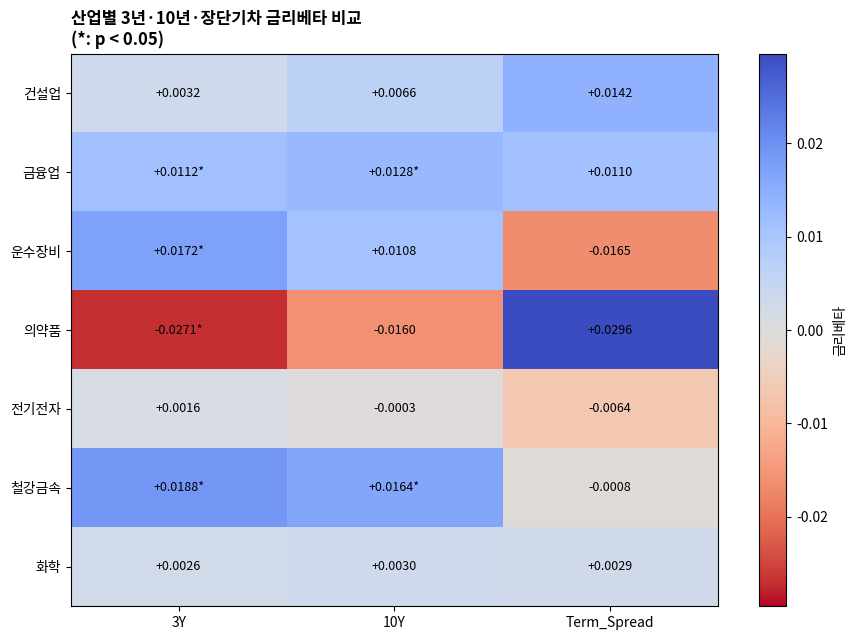

결과표 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/maturity_beta_comparison.csv
그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/01_maturity_beta_comparison_heatmap.png


In [8]:
maturity_path = config.H1_TABDIR / "maturity_beta_comparison.csv"

maturity_beta_comparison.to_csv(
    maturity_path,
    index=False,
    encoding="utf-8-sig",
)

maturity_matrix = maturity_beta_comparison.pivot(
    index="industry",
    columns="model",
    values="coefficient",
).reindex(columns=["3Y", "10Y", "Term_Spread"])

maturity_p_matrix = maturity_beta_comparison.pivot(
    index="industry",
    columns="model",
    values="p_value",
).reindex(columns=["3Y", "10Y", "Term_Spread"])

fig, ax = plt.subplots(figsize=(9, 6.5))

max_abs = np.nanmax(np.abs(maturity_matrix.to_numpy()))

image = ax.imshow(
    maturity_matrix.to_numpy(),
    cmap="coolwarm_r",  # 프로젝트 색상 규칙: 음(-) 빨강 / 양(+) 파랑 (STYLE_GUIDE §12)
    vmin=-max_abs,
    vmax=max_abs,
    aspect="auto",
)

ax.set_xticks(np.arange(len(maturity_matrix.columns)))
ax.set_xticklabels(maturity_matrix.columns)
ax.set_yticks(np.arange(len(maturity_matrix.index)))
ax.set_yticklabels(maturity_matrix.index)

for i in range(len(maturity_matrix.index)):
    for j in range(len(maturity_matrix.columns)):
        value = maturity_matrix.iloc[i, j]
        p_value = maturity_p_matrix.iloc[i, j]
        star = "*" if p_value < 0.05 else ""

        ax.text(
            j,
            i,
            f"{value:+.4f}{star}",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_title(
    "산업별 3년·10년·장단기차 금리베타 비교\n(*: p < 0.05)",
    loc="left",
    fontweight="bold",
)

fig.colorbar(image, ax=ax, label="금리베타")
fig.tight_layout()

maturity_fig_path = config.H1_FIGDIR / "01_maturity_beta_comparison_heatmap.png"
fig.savefig(maturity_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("결과표 저장:", maturity_path)
print("그림 저장:", maturity_fig_path)

# PART B. Nelson–Siegel Level·Slope·Curvature 동시모형

## 7단계. Nelson–Siegel 공통 λ

Nelson–Siegel 모형은 각 날짜의 금리를 다음 세 요인으로 설명한다.

$$
y_t(\tau)
=
\beta_{0,t}
+
\beta_{1,t}
\left(\frac{1-e^{-\lambda\tau}}{\lambda\tau}\right)
+
\beta_{2,t}
\left[
\frac{1-e^{-\lambda\tau}}{\lambda\tau}
-
e^{-\lambda\tau}
\right]
$$

- $\beta_0$: Level
- $\beta_1$: Slope
- $\beta_2$: Curvature

### λ는 무엇을 정하나

λ는 **곡률이 어느 만기를 보는지**를 정한다. 곡률 loading이 최대가 되는 만기는
$\tau \approx 1.7932/\lambda$ 이므로, **λ가 커질수록 곡률이 짧은 만기 쪽을 본다.**

### 왜 0.5로 고정하나

| | λ = 0.5 (기본값) | λ = 0.8041 (비교값) |
|---|---|---|
| 선택 기준 | **산업별 요인 분리** | 곡선 재구성 오차 최소 |
| 곡률이 보는 만기 | 약 3.6년 | 약 2.2년 |
| 곡선 적합도 | 다소 나쁨 | **최적** |
| 요인 분리 | **개선** | 나쁨 |

이 모형의 목적은 곡선을 정확히 묘사하는 것이 아니라
**Level·Slope·Curvature 각각에 대한 산업별 노출을 분리해 추정하는 것**이다.
요인이 서로 분리되지 않으면 "어느 요인 때문인가"라는 질문에 답할 수 없다.

곡선 적합도를 최소화하는 λ=0.8041에서는 Slope VIF가 9.5로 요인이 잘 나뉘지 않는다.
요인 간 다중공선성을 최소화하는 값은 0.52 부근이며, 소수점을 끌고 다니지 않도록
**0.5로 고정**한다(결과 차이는 무시할 수준).

**두 값은 절충 관계이며 어느 한쪽이 절대적으로 옳은 것은 아니다.**
아래에서 두 값의 적합도·분리도를 나란히 계산하고, 이후 분석은 기본값으로 진행한다.

> λ 선택에는 주가·검정통계량이 개입하지 않는다. 국고채 금리만으로 정한다.
> 값은 `config.NS_LAMBDA` 에서 관리한다.

In [9]:
MATURITIES = np.array([1.0, 3.0, 5.0, 10.0])

def nelson_siegel_loadings(maturities, lambda_value):
    maturities = np.asarray(maturities, dtype=float)

    slope_loading = (
        1.0 - np.exp(-lambda_value * maturities)
    ) / (
        lambda_value * maturities
    )

    curvature_loading = (
        slope_loading - np.exp(-lambda_value * maturities)
    )

    return np.column_stack([
        np.ones_like(maturities),
        slope_loading,
        curvature_loading,
    ])

yield_matrix = yield_wide[
    ["y1", "y3_new", "y5", "y10_new"]
].to_numpy(dtype=float)


def total_reconstruction_sse(lambda_value):
    """주어진 lambda 로 곡선을 재구성했을 때의 전체 제곱오차."""
    if lambda_value <= 0:
        return np.inf

    X = nelson_siegel_loadings(MATURITIES, lambda_value)
    betas = yield_matrix @ np.linalg.pinv(X).T
    return float(np.sum((yield_matrix - betas @ X.T) ** 2))


def factor_separation(lambda_value):
    """요인 간 최대 VIF. 값이 작을수록 요인이 잘 분리된다."""
    X = nelson_siegel_loadings(MATURITIES, lambda_value)
    betas = yield_matrix @ np.linalg.pinv(X).T
    d = pd.DataFrame(betas, columns=["L", "S", "C"]).diff().dropna()
    design = sm.add_constant(d, has_constant="add").to_numpy(dtype=float)
    return max(variance_inflation_factor(design, i + 1) for i in range(3))


# 기본값은 config 에서 가져온다(팀 합의값).
OPTIMAL_LAMBDA = config.NS_LAMBDA
COMPARE_LAMBDA = config.NS_LAMBDA_COMPARE

print(f"{'':10}{'lambda':>9}{'곡률정점':>10}{'재구성SSE':>12}{'최대VIF':>10}")
for lam, tag in [(OPTIMAL_LAMBDA, "기본값"), (COMPARE_LAMBDA, "비교값")]:
    print(f"{tag:<10}{lam:>9.4f}{1.7932/lam:>9.2f}년"
          f"{total_reconstruction_sse(lam):>12.6f}{factor_separation(lam):>10.2f}")

print()
print(f"이후 분석은 기본값 lambda = {OPTIMAL_LAMBDA} 로 진행한다.")
print("선택 기준: 산업별 요인 분리 (config.NS_LAMBDA)")


             lambda      곡률정점      재구성SSE     최대VIF
기본값          0.5000     3.59년    2.027876      7.17
비교값          0.8041     2.23년    1.158238      9.46

이후 분석은 기본값 lambda = 0.5 로 진행한다.
선택 기준: 산업별 요인 분리 (config.NS_LAMBDA)


### 7-1. λ 선택 근거 — 네 가지 기준 비교

λ는 연구자가 정하는 값이므로 **무슨 기준으로 정했는지**를 밝혀야 한다.
아래 네 기준은 **모두 국고채 금리만 사용한다. 주가와 검정통계량은 개입하지 않는다.**

| 기준 | 무엇을 최적화하나 |
|---|---|
| 곡선 재구성 오차 최소 | 곡선을 얼마나 정확히 묘사하는가 |
| **최대 VIF 최소** | **요인을 얼마나 잘 분리하는가** |
| \|corr(Slope, Curvature)\| 최소 | 두 요인의 직교성 |
| 요인 간 평균 \|상관\| 최소 | 전체 직교성 |

이 연구의 목적은 곡선 묘사가 아니라 **각 요인에 대한 산업별 노출을 분리해 추정하는 것**이므로
**요인 분리 기준**을 채택한다. 최적값은 0.52 부근이며 0.5로 고정한다.

In [10]:
from scipy.optimize import minimize_scalar


def lambda_diagnostics(lam):
    """λ 하나의 적합도·분리도. 주가는 쓰지 않는다."""
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    rmse = float(np.sqrt(np.mean((yield_matrix - B @ X.T) ** 2)))

    f = pd.DataFrame(B, columns=["Level", "Slope", "Curvature"]).diff().dropna()
    corr = f.corr()
    design = sm.add_constant(f, has_constant="add").to_numpy(dtype=float)
    vifs = [variance_inflation_factor(design, i + 1) for i in range(3)]

    return {"rmse": rmse, "max_vif": max(vifs),
            "abs_corr_SC": abs(float(corr.loc["Slope", "Curvature"])),
            "mean_abs_corr": float(np.mean([abs(corr.loc["Level", "Slope"]),
                                            abs(corr.loc["Slope", "Curvature"]),
                                            abs(corr.loc["Level", "Curvature"])]))}


rows = []
for name, key in [("곡선 재구성 오차 최소", "rmse"),
                  ("최대 VIF 최소 (채택 기준)", "max_vif"),
                  ("|corr(Slope,Curv)| 최소", "abs_corr_SC"),
                  ("요인 간 평균 |상관| 최소", "mean_abs_corr")]:
    r = minimize_scalar(lambda x: lambda_diagnostics(x)[key],
                        bounds=(0.05, 3.0), method="bounded", options={"xatol": 1e-6})
    st = lambda_diagnostics(r.x)
    rows.append({"기준": name, "최적 λ": round(r.x, 4),
                 "곡률정점(년)": round(1.7932 / r.x, 2),
                 "RMSE": round(st["rmse"], 5),
                 "최대VIF": round(st["max_vif"], 2),
                 "|corr(S,C)|": round(st["abs_corr_SC"], 3)})

lambda_criteria = pd.DataFrame(rows)
lambda_criteria.to_csv(config.H1_TABDIR / "lambda_selection_criteria.csv",
                       index=False, encoding="utf-8-sig")
display(lambda_criteria)

print(f"채택값 λ = {OPTIMAL_LAMBDA} (요인 분리 기준 0.52를 반올림)")
print(f"비교값 λ = {COMPARE_LAMBDA} (곡선 적합도 기준)")
print(f"참고: Diebold-Li(2006)는 곡률정점 30개월 고정 → λ = {1.7932/2.5:.4f}")


,기준,최적 λ,곡률정점(년),RMSE,최대VIF,"|corr(S,C)|"
0,곡선 재구성 오차 최소,0.8041,2.23,0.01084,9.46,0.559
1,최대 VIF 최소 (채택 기준),0.5202,3.45,0.01393,7.06,0.214
2,"|corr(Slope,Curv)| 최소",0.4334,4.14,0.01586,7.79,0.000
3,요인 간 평균 |상관| 최소,2.3739,0.76,0.02131,193.18,0.983


채택값 λ = 0.5 (요인 분리 기준 0.52를 반올림)
비교값 λ = 0.8041 (곡선 적합도 기준)
참고: Diebold-Li(2006)는 곡률정점 30개월 고정 → λ = 0.7173


### 7-2. λ 민감도 — 선택이 결론을 바꾸는가

λ를 0.2~2.0으로 바꿔가며 **결론이 흔들리는지** 확인한다.

- **동시검정** — 세 요인을 묶은 결과가 λ에 의존하는가
- **개별 계수** — 어느 요인이 유의해지는가
- **요인 겹침** — 어느 λ에서도 VIF가 높은가

개별 계수가 λ에 따라 달라지는 것은 요인이 회전하며 배정이 달라지기 때문이다.
**핵심은 동시검정 결과가 안정적인가**이다.

In [11]:
LAMBDA_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8041, 1.0, 1.5, 2.0]


def lambda_case(lam):
    """λ 하나에 대해 겹침 지표와 회귀 결론을 함께 계산한다."""
    X = nelson_siegel_loadings(MATURITIES, lam)
    B = yield_matrix @ np.linalg.pinv(X).T
    f = pd.DataFrame(B, index=yield_wide["date"],
                     columns=["L", "S", "C"]).diff().dropna()
    f.columns = ["d_L", "d_S", "d_C"]
    f = f.reset_index()

    dd = extended_panel[["date", "industry", "industry_return", "kospi_return"]]         .merge(f, on="date", how="inner")
    fac = ["d_L", "d_S", "d_C"]

    pvals, joint = [], {}
    for ind, g in dd.groupby("industry"):
        z = g[["industry_return", "kospi_return"] + fac].dropna()
        m = sm.OLS(z["industry_return"],
                   sm.add_constant(z[["kospi_return"] + fac], has_constant="add")
                   ).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        for v in fac:
            pvals.append({"industry": ind, "var": v, "p": m.pvalues[v]})
        joint[ind] = float(m.f_test("d_L = 0, d_S = 0, d_C = 0").pvalue)

    P = pd.DataFrame(pvals)
    P["p_bh"] = P.groupby("var")["p"].transform(
        lambda s: multipletests(s, method="fdr_bh")[1])

    st = lambda_diagnostics(lam)
    return {"lambda": lam, "곡률정점": round(1.7932 / lam, 2),
            "RMSE": round(st["rmse"], 5), "최대VIF": round(st["max_vif"], 2),
            "개별_원p유의": int((P["p"] < 0.05).sum()),
            "개별_BH유의": int((P["p_bh"] < 0.05).sum()),
            "동시검정_유의산업": int(sum(v < 0.05 for v in joint.values())),
            "의약품_동시p": round(joint.get("의약품", np.nan), 5),
            "운수장비_동시p": round(joint.get("운수장비", np.nan), 5)}


lambda_sensitivity = pd.DataFrame([lambda_case(l) for l in LAMBDA_GRID])
lambda_sensitivity.to_csv(config.H1_TABDIR / "lambda_sensitivity.csv",
                          index=False, encoding="utf-8-sig")
display(lambda_sensitivity)

print(f"동시검정 유의 산업 수 범위: "
      f"{lambda_sensitivity['동시검정_유의산업'].min()} ~ "
      f"{lambda_sensitivity['동시검정_유의산업'].max()}")
print(f"최대 VIF 최솟값: {lambda_sensitivity['최대VIF'].min():.2f}")


,lambda,곡률정점,RMSE,최대VIF,개별_원p유의,개별_BH유의,동시검정_유의산업,의약품_동시p,운수장비_동시p
0,0.2000,8.97,0.02214,52.08,3,0,3,0.00440,0.01317
1,0.3000,5.98,0.01929,13.68,5,4,3,0.00371,0.01310
2,0.4000,4.48,0.01668,8.37,4,3,3,0.00314,0.01309
3,0.5000,3.59,0.01435,7.17,3,2,3,0.00268,0.01313
4,0.6000,2.99,0.01248,7.54,3,0,3,0.00232,0.01322
5,0.8041,2.23,0.01084,9.46,1,0,3,0.00181,0.01348
6,1.0000,1.79,0.01196,12.44,1,0,3,0.00151,0.01376
7,1.5000,1.20,0.01720,31.00,1,0,3,0.00117,0.01434
8,2.0000,0.90,0.02023,88.81,1,0,3,0.00106,0.01463


동시검정 유의 산업 수 범위: 3 ~ 3
최대 VIF 최솟값: 7.17


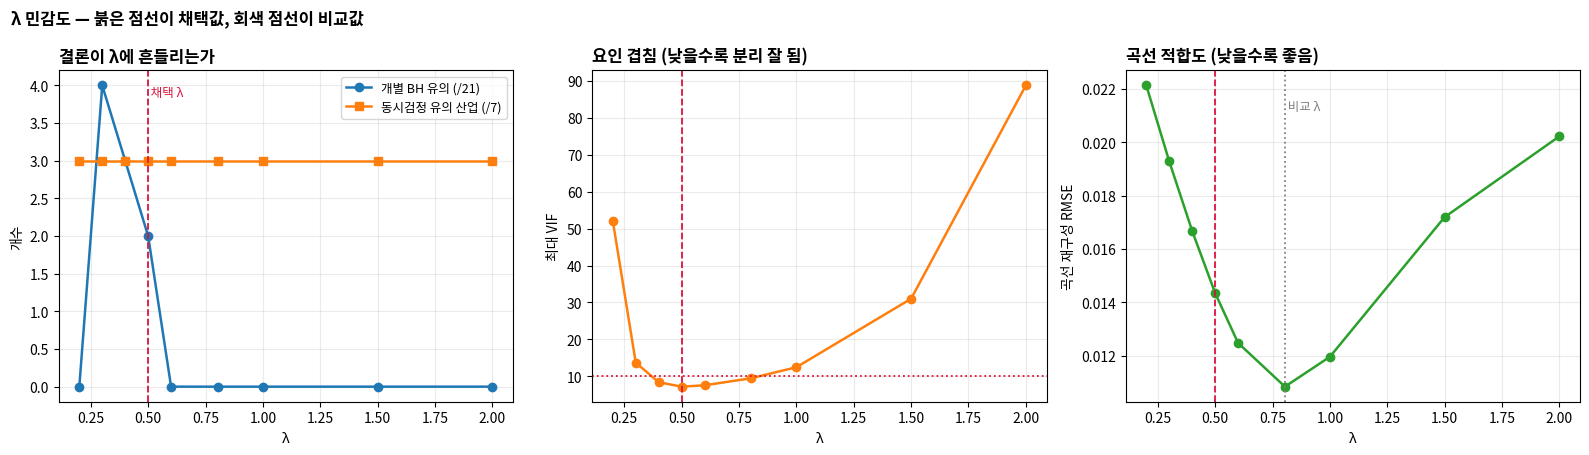

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/11_lambda_sensitivity.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["개별_BH유의"],
        marker="o", linewidth=1.8, label="개별 BH 유의 (/21)")
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["동시검정_유의산업"],
        marker="s", linewidth=1.8, label="동시검정 유의 산업 (/7)")
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.text(OPTIMAL_LAMBDA, ax.get_ylim()[1] * 0.95, " 채택 λ",
        color="crimson", fontsize=9, va="top")
ax.set_xlabel("λ"); ax.set_ylabel("개수")
ax.set_title("결론이 λ에 흔들리는가", loc="left", fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["최대VIF"],
        marker="o", linewidth=1.8, color="tab:orange")
ax.axhline(10, linestyle=":", color="crimson", linewidth=1.3)
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.set_xlabel("λ"); ax.set_ylabel("최대 VIF")
ax.set_title("요인 겹침 (낮을수록 분리 잘 됨)", loc="left", fontweight="bold")
ax.grid(alpha=0.25)

ax = axes[2]
ax.plot(lambda_sensitivity["lambda"], lambda_sensitivity["RMSE"],
        marker="o", linewidth=1.8, color="tab:green")
ax.axvline(OPTIMAL_LAMBDA, linestyle="--", color="crimson", linewidth=1.3)
ax.axvline(COMPARE_LAMBDA, linestyle=":", color="gray", linewidth=1.3)
ax.text(COMPARE_LAMBDA, ax.get_ylim()[1] * 0.95, " 비교 λ",
        color="gray", fontsize=9, va="top")
ax.set_xlabel("λ"); ax.set_ylabel("곡선 재구성 RMSE")
ax.set_title("곡선 적합도 (낮을수록 좋음)", loc="left", fontweight="bold")
ax.grid(alpha=0.25)

fig.suptitle("λ 민감도 — 붉은 점선이 채택값, 회색 점선이 비교값",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(config.H1_FIGDIR / "11_lambda_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()
print("그림 저장:", config.H1_FIGDIR / "11_lambda_sensitivity.png")



## 8단계. 날짜별 Level·Slope·Curvature와 변화량 생성

회귀에서는 요인의 수준값이 아니라 **일별 변화량**을 사용한다.

- `d_ns_level`
- `d_ns_slope`
- `d_ns_curvature`

산업수익률도 일별 변화율이기 때문에 설명변수의 시점 단위를 맞추는 과정이다.


In [13]:
ns_loadings = nelson_siegel_loadings(
    MATURITIES,
    OPTIMAL_LAMBDA,
)

ns_pseudo_inverse = np.linalg.pinv(ns_loadings)
ns_betas = yield_matrix @ ns_pseudo_inverse.T
fitted_yields = ns_betas @ ns_loadings.T

ns_factors = yield_wide[["date"]].copy()
ns_factors["ns_level"] = ns_betas[:, 0]
ns_factors["ns_slope"] = ns_betas[:, 1]
ns_factors["ns_curvature"] = ns_betas[:, 2]

residuals = yield_matrix - fitted_yields
ns_factors["curve_rmse"] = np.sqrt(np.mean(residuals ** 2, axis=1))

for factor in ["ns_level", "ns_slope", "ns_curvature"]:
    ns_factors[f"d_{factor}"] = ns_factors[factor].diff()

print("Nelson–Siegel 요인 생성 완료")
display(ns_factors.head())
display(ns_factors["curve_rmse"].describe().to_frame("curve_rmse"))

Nelson–Siegel 요인 생성 완료


,date,ns_level,ns_slope,ns_curvature,curve_rmse,d_ns_level,d_ns_slope,d_ns_curvature
0,2016-01-04,2.482510,-0.772935,-1.499847,0.004748,NaN,NaN,NaN
1,2016-01-05,2.503357,-0.808165,-1.478302,0.004711,0.020847,-0.035229,0.021545
2,2016-01-06,2.459071,-0.773539,-1.392845,0.006932,-0.044286,0.034626,0.085457
3,2016-01-07,2.415300,-0.741832,-1.303817,0.006067,-0.043771,0.031707,0.089028
4,2016-01-08,2.466221,-0.795600,-1.295521,0.005690,0.050921,-0.053768,0.008296


,curve_rmse
count,2462.000000
mean,0.010496
std,0.009787
min,0.000002
25%,0.003064
50%,0.007294
75%,0.015481
max,0.068426


In [14]:
factor_cols = [
    "date",
    "ns_level",
    "ns_slope",
    "ns_curvature",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "curve_rmse",
]

extended_panel = (
    extended_panel
    .drop(
        columns=[c for c in factor_cols if c != "date" and c in extended_panel.columns],
        errors="ignore",
    )
    .merge(
        ns_factors[factor_cols],
        on="date",
        how="inner",
        validate="many_to_one",
    )
    .sort_values(["date", "industry"])
    .reset_index(drop=True)
)

extended_panel.to_csv(
    config.EXTENDED_PANEL_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Nelson–Siegel 요인까지 포함한 최종 패널 저장 완료")
print("저장 경로:", config.EXTENDED_PANEL_PATH)
display(extended_panel.head())

Nelson–Siegel 요인까지 포함한 최종 패널 저장 완료
저장 경로: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/data/processed/industry_rate_panel_extended.csv


,date,industry,industry_index,industry_return,kospi_index,kospi_return,y3,d_y3,y10,d_y10,...,corp_aa3,credit_spread,d_credit_spread,ns_level,ns_slope,ns_curvature,d_ns_level,d_ns_slope,d_ns_curvature,curve_rmse
0,2016-01-04,건설업,104.43,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
1,2016-01-04,금융업,408.22,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
2,2016-01-04,운수장비,1731.95,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
3,2016-01-04,의약품,8411.35,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748
4,2016-01-04,전기전자,9239.12,NaN,1918.76,NaN,1.634,NaN,2.039,NaN,...,2.093,0.459,NaN,2.48251,-0.772935,-1.499847,NaN,NaN,NaN,0.004748



## 9단계. Level·Slope·Curvature 동시모형 추정

각 산업별 회귀식은 다음과 같다.

$$
R_{i,t}
=
\alpha_i
+
\beta_{M,i}R_{M,t}
+
\beta_{L,i}\Delta Level_t
+
\beta_{S,i}\Delta Slope_t
+
\beta_{C,i}\Delta Curvature_t
+
\epsilon_{i,t}
$$

### 왜 세 요인을 동시에 넣나?

Level·Slope·Curvature가 서로 다른 금리곡선 움직임을 설명하므로, 세 요인을 함께 넣어야 다른 요인을 통제한 뒤 각 요인의 고유한 민감도를 추정할 수 있다.


In [15]:
def run_yield_curve_factor_model(data, hac_lags=5, x_cols=None, factor_labels=None):
    """산업별 다요인 동시모형(HAC). x_cols / factor_labels 로 요인 구성을 바꾼다."""
    if x_cols is None:
        x_cols = [
            "kospi_return",
            "d_ns_level",
            "d_ns_slope",
            "d_ns_curvature",
        ]

    if factor_labels is None:
        factor_labels = {
            "d_ns_level": "Level",
            "d_ns_slope": "Slope",
            "d_ns_curvature": "Curvature",
        }

    rows = []

    for industry, group in data.groupby("industry"):
        reg_data = group[
            ["industry_return"] + x_cols
        ].dropna()

        X = sm.add_constant(
            reg_data[x_cols],
            has_constant="add",
        )
        y = reg_data["industry_return"]

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": hac_lags},
        )

        ci = model.conf_int()

        for variable, factor in factor_labels.items():
            rows.append({
                "industry": industry,
                "factor": factor,
                "variable": variable,
                "coefficient": model.params[variable],
                "std_error_hac": model.bse[variable],
                "t_value": model.tvalues[variable],
                "p_value": model.pvalues[variable],
                "ci_lower_95": ci.loc[variable, 0],
                "ci_upper_95": ci.loc[variable, 1],
                "significant_5pct": model.pvalues[variable] < 0.05,
                "market_beta": model.params["kospi_return"],
                "r_squared": model.rsquared,
                "adj_r_squared": model.rsquared_adj,
                "n_obs": int(model.nobs),
                "hac_lags": hac_lags,
                "optimal_lambda": OPTIMAL_LAMBDA,
            })

    return pd.DataFrame(rows)

yield_curve_factor_betas = run_yield_curve_factor_model(
    extended_panel,
    hac_lags=HAC_LAGS,
)

display(yield_curve_factor_betas.round(6))

,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,건설업,Level,d_ns_level,-0.021038,0.019810,-1.061952,0.288258,-0.059866,0.017790,False,1.013279,0.399432,0.398449,2451,5,0.5
1,건설업,Slope,d_ns_slope,-0.027805,0.018091,-1.536940,0.124308,-0.063263,0.007653,False,1.013279,0.399432,0.398449,2451,5,0.5
2,건설업,Curvature,d_ns_curvature,-0.002338,0.003058,-0.764503,0.444568,-0.008330,0.003655,False,1.013279,0.399432,0.398449,2451,5,0.5
3,금융업,Level,d_ns_level,0.017979,0.008254,2.178290,0.029384,0.001802,0.034156,True,0.925754,0.623471,0.622855,2451,5,0.5
4,금융업,Slope,d_ns_slope,0.007189,0.007423,0.968519,0.332785,-0.007359,0.021737,False,0.925754,0.623471,0.622855,2451,5,0.5
5,금융업,Curvature,d_ns_curvature,0.002413,0.001370,1.762013,0.078067,-0.000271,0.005097,False,0.925754,0.623471,0.622855,2451,5,0.5
6,운수장비,Level,d_ns_level,0.013579,0.012917,1.051196,0.293168,-0.011739,0.038896,False,1.006309,0.472321,0.471458,2451,5,0.5
7,운수장비,Slope,d_ns_slope,0.009915,0.012103,0.819256,0.412641,-0.013806,0.033636,False,1.006309,0.472321,0.471458,2451,5,0.5
8,운수장비,Curvature,d_ns_curvature,0.006207,0.002310,2.687189,0.007206,0.001680,0.010735,True,1.006309,0.472321,0.471458,2451,5,0.5
9,의약품,Level,d_ns_level,-0.013817,0.015855,-0.871495,0.383484,-0.044891,0.017257,False,0.789172,0.243525,0.242288,2451,5,0.5



## 10단계. 산업별 계수·SE·t·p·95% 신뢰구간 표 저장

이 표가 Nelson–Siegel 다요인 모형의 핵심 결과표다.

- `coefficient`: 산업별 민감도
- `std_error_hac`: HAC 표준오차
- `t_value`: t 통계량
- `p_value`: 유의확률
- `ci_lower_95`, `ci_upper_95`: 95% 신뢰구간


In [16]:
factor_path = config.H1_TABDIR / "yield_curve_factor_betas.csv"

yield_curve_factor_betas.to_csv(
    factor_path,
    index=False,
    encoding="utf-8-sig",
)

print("결과표 저장 완료:", factor_path)

결과표 저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/yield_curve_factor_betas.csv



## 11단계. 산업별 수익률곡선 요인 민감도 Heatmap

한 산업이 Level·Slope·Curvature 중 어떤 요인에 상대적으로 더 크게 반응하는지 한눈에 비교한다.

별표는 5% 수준에서 유의함을 의미한다.


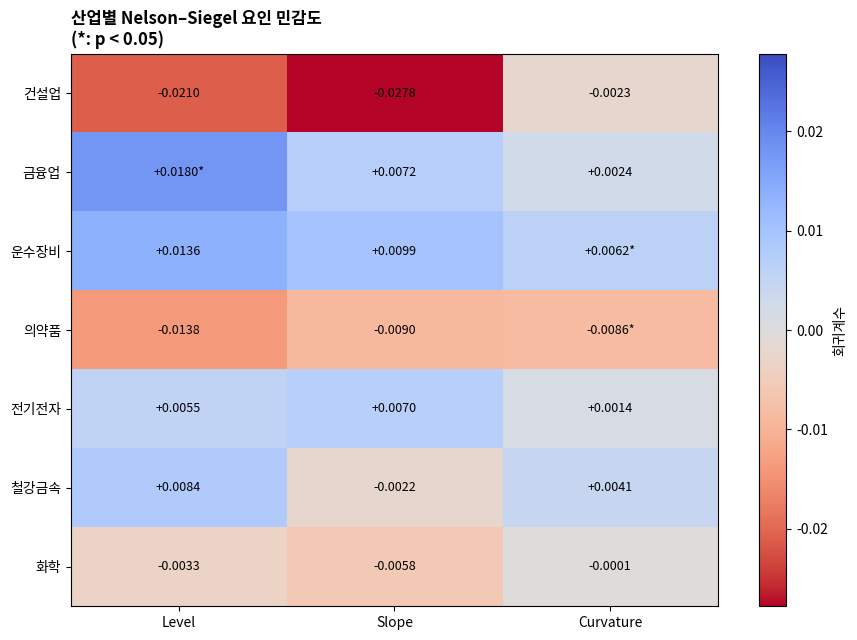

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/02_yield_curve_factor_beta_heatmap.png


In [17]:
factor_order = ["Level", "Slope", "Curvature"]

coef_matrix = yield_curve_factor_betas.pivot(
    index="industry",
    columns="factor",
    values="coefficient",
).reindex(columns=factor_order)

p_matrix = yield_curve_factor_betas.pivot(
    index="industry",
    columns="factor",
    values="p_value",
).reindex(index=coef_matrix.index, columns=factor_order)

fig, ax = plt.subplots(figsize=(9, 6.5))

max_abs = np.nanmax(np.abs(coef_matrix.to_numpy()))

image = ax.imshow(
    coef_matrix.to_numpy(),
    cmap="coolwarm_r",  # 프로젝트 색상 규칙: 음(-) 빨강 / 양(+) 파랑 (STYLE_GUIDE §12)
    vmin=-max_abs,
    vmax=max_abs,
    aspect="auto",
)

ax.set_xticks(np.arange(len(factor_order)))
ax.set_xticklabels(factor_order)
ax.set_yticks(np.arange(len(coef_matrix.index)))
ax.set_yticklabels(coef_matrix.index)

for i in range(len(coef_matrix.index)):
    for j in range(len(factor_order)):
        value = coef_matrix.iloc[i, j]
        p_value = p_matrix.iloc[i, j]
        star = "*" if p_value < 0.05 else ""

        ax.text(
            j,
            i,
            f"{value:+.4f}{star}",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_title(
    "산업별 Nelson–Siegel 요인 민감도\n(*: p < 0.05)",
    loc="left",
    fontweight="bold",
)

fig.colorbar(image, ax=ax, label="회귀계수")
fig.tight_layout()

factor_fig_path = config.H1_FIGDIR / "02_yield_curve_factor_beta_heatmap.png"
fig.savefig(factor_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", factor_fig_path)


## 12단계. 요인별 계수 플롯

각 요인에 대해 산업별 계수와 95% 신뢰구간을 비교한다.

신뢰구간이 0을 지나지 않으면 해당 요인의 산업별 민감도가 5% 수준에서 유의하다.


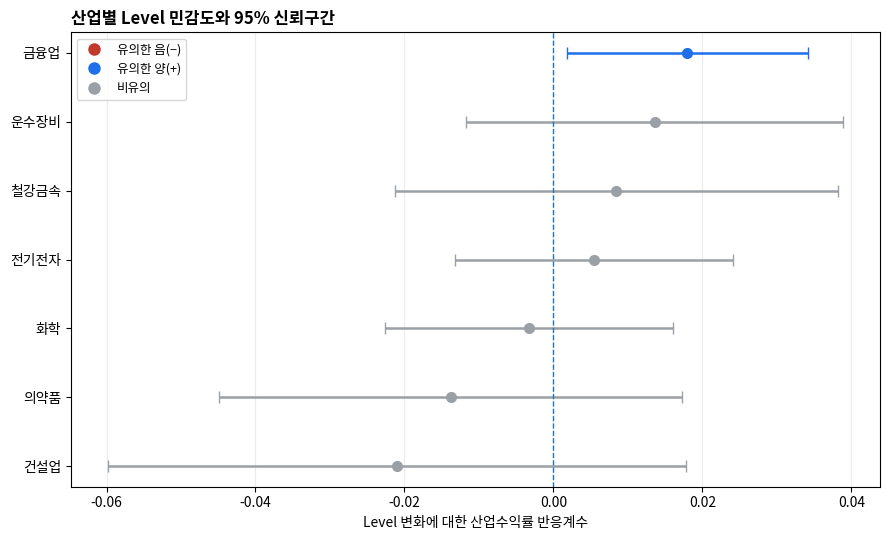

저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/03_level_coefficient_plot.png


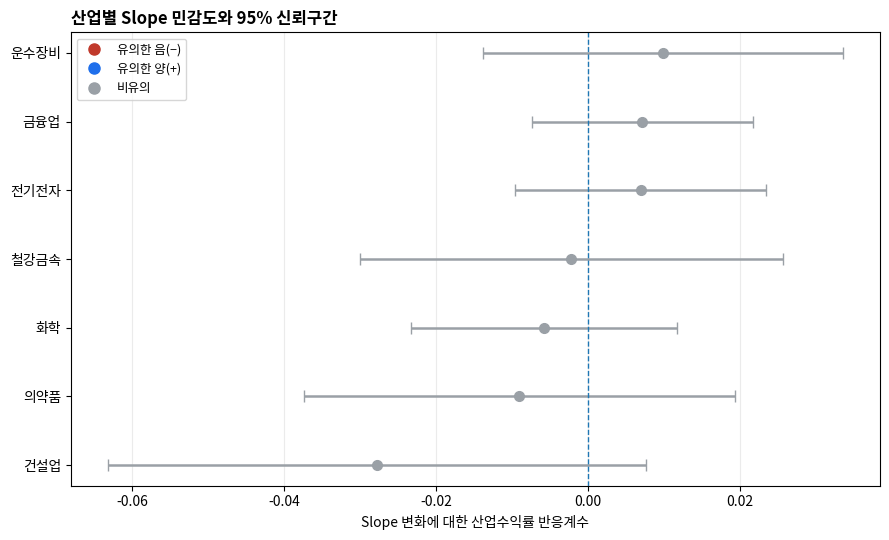

저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/03_slope_coefficient_plot.png


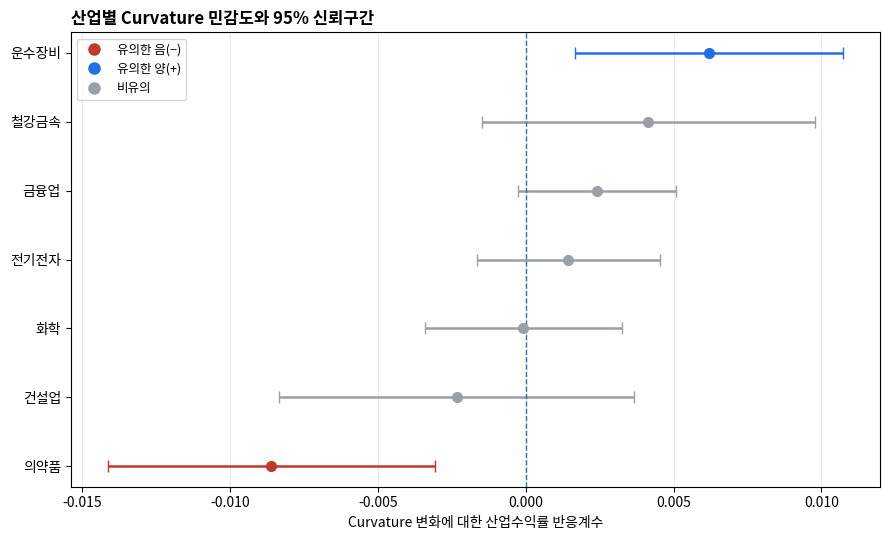

저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/03_curvature_coefficient_plot.png


In [18]:
for factor in factor_order:
    plot_data = (
        yield_curve_factor_betas[
            yield_curve_factor_betas["factor"] == factor
        ]
        .sort_values("coefficient")
        .reset_index(drop=True)
    )

    y_pos = np.arange(len(plot_data))

    lower_error = (
        plot_data["coefficient"] - plot_data["ci_lower_95"]
    )
    upper_error = (
        plot_data["ci_upper_95"] - plot_data["coefficient"]
    )

    # 부호 색상 규칙(STYLE_GUIDE §12): 유의 판정은 p_value < 0.05(significant_5pct) 기준.
    point_colors = [
        config.sign_color(coef, sig)
        for coef, sig in zip(plot_data["coefficient"], plot_data["significant_5pct"])
    ]

    fig, ax = plt.subplots(figsize=(9, 5.5))

    for y, coef, lo, hi, color in zip(
        y_pos, plot_data["coefficient"], lower_error, upper_error, point_colors,
    ):
        ax.errorbar(
            coef, y,
            xerr=[[lo], [hi]],
            fmt="o",
            capsize=4,
            linewidth=1.8,
            markersize=7,
            color=color,
            ecolor=color,
        )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_data["industry"])
    ax.set_xlabel(f"{factor} 변화에 대한 산업수익률 반응계수")
    ax.set_title(
        f"산업별 {factor} 민감도와 95% 신뢰구간",
        loc="left",
        fontweight="bold",
    )
    ax.grid(axis="x", alpha=0.25)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["ns"], label="비유의"),
    ]
    ax.legend(handles=legend_handles, loc="best", frameon=True, fontsize=9)

    fig.tight_layout()

    path = config.H1_FIGDIR / f"03_{factor.lower()}_coefficient_plot.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

    print("저장 완료:", path)

# PART C. Credit Spread 강건성 검증 (B-2)

## 12단계. Credit Spread 단독모형

먼저 Credit Spread 하나만 넣은 2지수 모형을 본다.

$$
R_{i,t}=\alpha_i+\beta_{M,i}R_{M,t}+\beta_{Credit,i}\Delta CreditSpread_t+\epsilon_{i,t}
$$

5단계에서 만든 `run_single_rate_models()`를 `model_specs` 인자만 바꿔 그대로 재사용한다.
새 함수를 만들지 않으므로 만기별 비교 결과는 영향을 받지 않는다.

### 부호를 어떻게 읽나 (결과를 보기 전에 먼저 적어 둔다)

`d_credit_spread`가 양(+)이라는 것은 **신용스프레드 확대 = 신용위험 악화**를 뜻한다.
따라서 계수가 음(−)이면 신용위험이 커질 때 그 산업 주가가 더 많이 떨어진다는 의미다.

- **건설업·화학·철강금속** — 레버리지가 높고 경기민감도가 커서 음(−) 예상
- **의약품** — 방어적 성격이 강해 0에 가까울 것으로 예상
- **금융업 — 사전 예상 없음 (No directional prior)**

금융업을 왜 비워 두는지는 아래 13단계 뒤에 따로 적는다.


In [19]:
# Credit Spread 단독모형.
# model_specs 만 갈아끼우고 함수는 5단계 것을 그대로 쓴다.
credit_spread_single = run_single_rate_models(
    extended_panel,
    hac_lags=HAC_LAGS,
    model_specs={"Credit_Spread": "d_credit_spread"},
)

display(credit_spread_single.round(6))


,industry,model,rate_variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,n_obs,hac_lags
0,건설업,Credit_Spread,d_credit_spread,-0.006627,0.033401,-0.198415,0.842721,-0.072092,0.058838,False,1.015018,0.398200,2451,5
1,금융업,Credit_Spread,d_credit_spread,-0.035308,0.020979,-1.682981,0.092379,-0.076427,0.005811,False,0.925408,0.622364,2451,5
2,운수장비,Credit_Spread,d_credit_spread,-0.057150,0.030019,-1.903785,0.056938,-0.115986,0.001686,False,1.002731,0.471308,2451,5
3,의약품,Credit_Spread,d_credit_spread,0.110007,0.041327,2.661862,0.007771,0.029007,0.191007,True,0.793752,0.242992,2451,5
4,전기전자,Credit_Spread,d_credit_spread,-0.001354,0.018067,-0.074965,0.940242,-0.036765,0.034056,False,1.205398,0.719268,2451,5
5,철강금속,Credit_Spread,d_credit_spread,-0.064747,0.028716,-2.254782,0.024147,-0.121029,-0.008466,True,1.023287,0.382886,2451,5
6,화학,Credit_Spread,d_credit_spread,0.018430,0.019754,0.932976,0.350832,-0.020287,0.057147,False,1.053827,0.643730,2451,5


## 13단계. Credit Spread 포함 확장모형

$$
R_{i,t}
=
\alpha_i
+
\beta_{M,i}R_{M,t}
+
\beta_{L,i}\Delta Level_t
+
\beta_{S,i}\Delta Slope_t
+
\beta_{C,i}\Delta Curvature_t
+
\beta_{Credit,i}\Delta CreditSpread_t
+
\epsilon_{i,t}
$$

9단계의 `run_yield_curve_factor_model()`에 `x_cols`·`factor_labels`만 넘겨 재사용한다.

### 주의 — 9단계 계수는 바뀌는 것이 정상이다

설명변수를 추가하면 기존 Level·Slope·Curvature 계수는 **반드시** 달라진다.
그게 통제변수를 넣는 목적이므로, 값이 변한 것 자체는 오류가 아니다.
강건성 판단 기준은 **부호와 유의성이 유지되는가**이다.

그래서 B-1이 만든 `yield_curve_factor_betas.csv`는 건드리지 않고,
확장모형 결과는 `credit_spread_betas.csv`에 4개 요인을 모두 담아 따로 저장한다.
두 파일을 나란히 놓고 비교할 수 있게 하기 위해서다.


In [20]:
# 확장모형: 기존 3요인 + Credit Spread
CREDIT_X_COLS = [
    "kospi_return",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "d_credit_spread",
]

CREDIT_FACTOR_LABELS = {
    "d_ns_level": "Level",
    "d_ns_slope": "Slope",
    "d_ns_curvature": "Curvature",
    "d_credit_spread": "CreditSpread",
}

credit_spread_extended = run_yield_curve_factor_model(
    extended_panel,
    hac_lags=HAC_LAGS,
    x_cols=CREDIT_X_COLS,
    factor_labels=CREDIT_FACTOR_LABELS,
)

display(credit_spread_extended.round(6))


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,건설업,Level,d_ns_level,-0.021001,0.020021,-1.048935,0.294208,-0.060241,0.018240,False,1.013283,0.399432,0.398204,2451,5,0.5
1,건설업,Slope,d_ns_slope,-0.027787,0.018219,-1.525172,0.127216,-0.063495,0.007921,False,1.013283,0.399432,0.398204,2451,5,0.5
2,건설업,Curvature,d_ns_curvature,-0.002313,0.003354,-0.689571,0.490464,-0.008888,0.004261,False,1.013283,0.399432,0.398204,2451,5,0.5
3,건설업,CreditSpread,d_credit_spread,0.000816,0.036832,0.022153,0.982326,-0.071374,0.073006,False,1.013283,0.399432,0.398204,2451,5,0.5
4,금융업,Level,d_ns_level,0.016651,0.008259,2.016157,0.043784,0.000464,0.032838,True,0.925611,0.623810,0.623041,2451,5,0.5
5,금융업,Slope,d_ns_slope,0.006531,0.007489,0.872113,0.383147,-0.008147,0.021209,False,0.925611,0.623810,0.623041,2451,5,0.5
6,금융업,Curvature,d_ns_curvature,0.001543,0.001584,0.974326,0.329895,-0.001561,0.004648,False,0.925611,0.623810,0.623041,2451,5,0.5
7,금융업,CreditSpread,d_credit_spread,-0.029060,0.024413,-1.190334,0.233915,-0.076908,0.018789,False,0.925611,0.623810,0.623041,2451,5,0.5
8,운수장비,Level,d_ns_level,0.012290,0.012796,0.960495,0.336806,-0.012789,0.037370,False,1.006170,0.472527,0.471448,2451,5,0.5
9,운수장비,Slope,d_ns_slope,0.009277,0.012030,0.771116,0.440638,-0.014302,0.032855,False,1.006170,0.472527,0.471448,2451,5,0.5


### 금융업에 방향을 가정하지 않는 이유

금융업은 신용스프레드 확대가 서로 반대 방향으로 작동한다.

- **음(−) 방향** — 차주 부실 위험 증가, 대손충당금 부담, 조달비용 상승
- **양(+) 방향** — 대출 스프레드 확대에 따른 마진 개선, 위험보상 상승

또한 국내 '금융업' 지수는 은행·보험·증권이 섞여 있어 하위업종별 반응이 상쇄될 수 있다.
둘 중 어느 쪽이 클지는 이론적으로 결정되지 않으므로,
금융업은 **사전 예상 없음(No directional prior)** 으로 둔다.

이는 결과를 본 뒤 설명을 만들어 붙이는 것(HARKing)을 막기 위한 장치다.
금융업 계수가 어떤 부호로 나오든, 그 부호에 맞춘 사후 가설로 바꾸어 적지 않는다.
결과는 그대로 보고하고, 해석은 **탐색적(exploratory)** 이라고 명시한다.


## 14단계. BH(FDR) 보정과 결과표 저장

### 검정족(family)을 어떻게 잡았나

**(모형, 요인) 안의 7개 산업**을 하나의 검정족으로 본다.

이는 새로 정한 기준이 아니라 이 프로젝트의 기존 선례를 그대로 따른 것이다.
`src/models.py`의 `industry_rate_betas()`는 하나의 모형에서 나온 7개 산업 p값에
`multipletests(..., method="fdr_bh")`를 적용하고,
Baseline summary도 "7개 산업 공동 BH 보정"으로 기술하고 있다.

요인을 가로질러 28개(7산업 x 4요인)를 한 번에 보정하면
기존 결과와 기준이 어긋나고 검정력만 잃는다.


In [21]:
def add_bh_correction(result, group_cols=("model", "factor"),
                      p_col="p_value", alpha=0.05):
    """검정족별 BH(FDR) 보정 p값을 붙인다. 원 p_value 는 그대로 둔다."""
    out = result.copy()
    group_cols = list(group_cols)

    out["p_value_bh"] = np.nan
    out["bh_n_tests"] = 0

    for keys, idx in out.groupby(group_cols).groups.items():
        pvals = out.loc[idx, p_col].to_numpy(dtype=float)
        out.loc[idx, "p_value_bh"] = multipletests(pvals, method="fdr_bh")[1]
        out.loc[idx, "bh_n_tests"] = len(pvals)

    # 어떤 단위로 보정했는지 표에 남겨 두어야 나중에 재검토가 가능하다.
    out["bh_family"] = out[group_cols].astype(str).agg(" | ".join, axis=1)
    out["significant_5pct_bh"] = out["p_value_bh"] < alpha

    return out


In [22]:
# 단독모형과 확장모형의 컬럼 구성을 맞춘 뒤 하나의 표로 합친다.
# (단독모형은 rate_variable, 확장모형은 variable/factor 를 쓴다)
credit_single_norm = (
    credit_spread_single
    .rename(columns={"rate_variable": "variable"})
    .assign(
        model="A_Credit_Single",
        factor="CreditSpread",
        adj_r_squared=np.nan,
        optimal_lambda=np.nan,
    )
)

credit_extended_norm = credit_spread_extended.assign(model="B_Extended_4Factor")

CREDIT_TABLE_COLS = [
    "model",
    "industry",
    "factor",
    "variable",
    "coefficient",
    "std_error_hac",
    "t_value",
    "p_value",
    "p_value_bh",
    "bh_family",
    "bh_n_tests",
    "ci_lower_95",
    "ci_upper_95",
    "significant_5pct",
    "significant_5pct_bh",
    "market_beta",
    "r_squared",
    "adj_r_squared",
    "n_obs",
    "hac_lags",
    "optimal_lambda",
]

credit_spread_betas = (
    pd.concat([credit_single_norm, credit_extended_norm], ignore_index=True)
    .pipe(add_bh_correction, group_cols=("model", "factor"))
    .sort_values(["model", "factor", "industry"])
    .reset_index(drop=True)
    .reindex(columns=CREDIT_TABLE_COLS)
)

credit_path = config.H1_TABDIR / "credit_spread_betas.csv"

credit_spread_betas.to_csv(
    credit_path,
    index=False,
    encoding="utf-8-sig",
)

print("결과표 저장 완료:", credit_path)
display(credit_spread_betas.round(6))


결과표 저장 완료:

 /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/credit_spread_betas.csv


,model,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,p_value_bh,bh_family,...,ci_lower_95,ci_upper_95,significant_5pct,significant_5pct_bh,market_beta,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda
0,A_Credit_Single,건설업,CreditSpread,d_credit_spread,-0.006627,0.033401,-0.198415,0.842721,0.940242,A_Credit_Single | CreditSpread,...,-0.072092,0.058838,False,False,1.015018,0.398200,NaN,2451,5,NaN
1,A_Credit_Single,금융업,CreditSpread,d_credit_spread,-0.035308,0.020979,-1.682981,0.092379,0.161663,A_Credit_Single | CreditSpread,...,-0.076427,0.005811,False,False,0.925408,0.622364,NaN,2451,5,NaN
2,A_Credit_Single,운수장비,CreditSpread,d_credit_spread,-0.057150,0.030019,-1.903785,0.056938,0.132856,A_Credit_Single | CreditSpread,...,-0.115986,0.001686,False,False,1.002731,0.471308,NaN,2451,5,NaN
3,A_Credit_Single,의약품,CreditSpread,d_credit_spread,0.110007,0.041327,2.661862,0.007771,0.054397,A_Credit_Single | CreditSpread,...,0.029007,0.191007,True,False,0.793752,0.242992,NaN,2451,5,NaN
4,A_Credit_Single,전기전자,CreditSpread,d_credit_spread,-0.001354,0.018067,-0.074965,0.940242,0.940242,A_Credit_Single | CreditSpread,...,-0.036765,0.034056,False,False,1.205398,0.719268,NaN,2451,5,NaN
5,A_Credit_Single,철강금속,CreditSpread,d_credit_spread,-0.064747,0.028716,-2.254782,0.024147,0.084515,A_Credit_Single | CreditSpread,...,-0.121029,-0.008466,True,False,1.023287,0.382886,NaN,2451,5,NaN
6,A_Credit_Single,화학,CreditSpread,d_credit_spread,0.018430,0.019754,0.932976,0.350832,0.491165,A_Credit_Single | CreditSpread,...,-0.020287,0.057147,False,False,1.053827,0.643730,NaN,2451,5,NaN
7,B_Extended_4Factor,건설업,CreditSpread,d_credit_spread,0.000816,0.036832,0.022153,0.982326,0.982326,B_Extended_4Factor | CreditSpread,...,-0.071374,0.073006,False,False,1.013283,0.399432,0.398204,2451,5,0.5
8,B_Extended_4Factor,금융업,CreditSpread,d_credit_spread,-0.029060,0.024413,-1.190334,0.233915,0.409352,B_Extended_4Factor | CreditSpread,...,-0.076908,0.018789,False,False,0.925611,0.623810,0.623041,2451,5,0.5
9,B_Extended_4Factor,운수장비,CreditSpread,d_credit_spread,-0.028199,0.032764,-0.860672,0.389419,0.545186,B_Extended_4Factor | CreditSpread,...,-0.092415,0.036017,False,False,1.006170,0.472527,0.471448,2451,5,0.5


## 15단계. 요인 상관행렬과 VIF

### 왜 확인하나

Level·Slope·Curvature는 같은 4개 만기 금리를 고정된 가중치로 변환해 만든 값이다.
서로 독립이라는 보장이 없고, 여기에 Credit Spread까지 넣으면
계수 추정이 불안정해질 수 있다.

VIF는 관행적으로 10을 넘으면 주의, 5를 넘으면 점검 대상으로 본다.

### 왜 날짜 단위로 계산하나

패널은 같은 날짜가 산업 수만큼 반복되어 쌓여 있다.
설명변수는 모든 산업이 공유하므로, 날짜를 중복 제거하지 않으면
표본 수만 7배로 부풀고 상관·VIF의 의미가 흐려진다.


In [23]:
VIF_VARS = [
    "kospi_return",
    "d_ns_level",
    "d_ns_slope",
    "d_ns_curvature",
    "d_credit_spread",
]

# 설명변수는 모든 산업이 공유하므로 날짜 기준으로 한 번씩만 남긴다.
factor_daily = (
    extended_panel[["date"] + VIF_VARS]
    .drop_duplicates(subset="date")
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

corr_matrix = factor_daily[VIF_VARS].corr()

# VIF 는 상수항을 포함한 설계행렬에서 계산해야 값이 왜곡되지 않는다.
vif_design = sm.add_constant(factor_daily[VIF_VARS], has_constant="add")

vif_values = {
    var: variance_inflation_factor(vif_design.to_numpy(dtype=float), i)
    for i, var in enumerate(vif_design.columns)
    if var != "const"
}

factor_correlation_vif = (
    corr_matrix
    .rename(columns=lambda c: f"corr_{c}")
    .reset_index()
    .rename(columns={"index": "variable"})
    .assign(
        vif=lambda d: d["variable"].map(vif_values),
        n_obs=len(factor_daily),
    )
)

# variable / vif / n_obs 를 앞으로 빼서 읽기 쉽게 한다.
factor_correlation_vif = factor_correlation_vif[
    ["variable", "vif", "n_obs"]
    + [c for c in factor_correlation_vif.columns if c.startswith("corr_")]
]

vif_path = config.H1_TABDIR / "factor_correlation_vif.csv"

factor_correlation_vif.to_csv(
    vif_path,
    index=False,
    encoding="utf-8-sig",
)

print("상관·VIF 표 저장 완료:", vif_path)
print("VIF 5 초과 변수:", [v for v, x in vif_values.items() if x > 5])
display(factor_correlation_vif.round(4))


상관·VIF 표 저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/factor_correlation_vif.csv
VIF 5 초과 변수: ['d_ns_level', 'd_ns_slope']


,variable,vif,n_obs,corr_kospi_return,corr_d_ns_level,corr_d_ns_slope,corr_d_ns_curvature,corr_d_credit_spread
0,kospi_return,1.0061,2451,1.0000,0.0175,-0.0101,-0.0615,0.0212
1,d_ns_level,7.2545,2451,0.0175,1.0000,-0.8429,-0.2360,-0.0202
2,d_ns_slope,7.0136,2451,-0.0101,-0.8429,1.0000,-0.1727,0.1627
3,d_ns_curvature,2.4474,2451,-0.0615,-0.2360,-0.1727,1.0000,-0.4112
4,d_credit_spread,1.2284,2451,0.0212,-0.0202,0.1627,-0.4112,1.0000


## 16단계. 4요인 계수 신뢰구간 그림

12단계 그림과 같은 errorbar 스타일을 그대로 쓰고, 패널만 4개로 늘린다.
신뢰구간이 세로 0선을 지나지 않으면 5% 수준에서 유의하다.

파일명은 저장소 명명규칙(`01_`~`03_` 숫자 접두)을 따라
`04_yield_curve_factor_ci.png`로 저장한다.


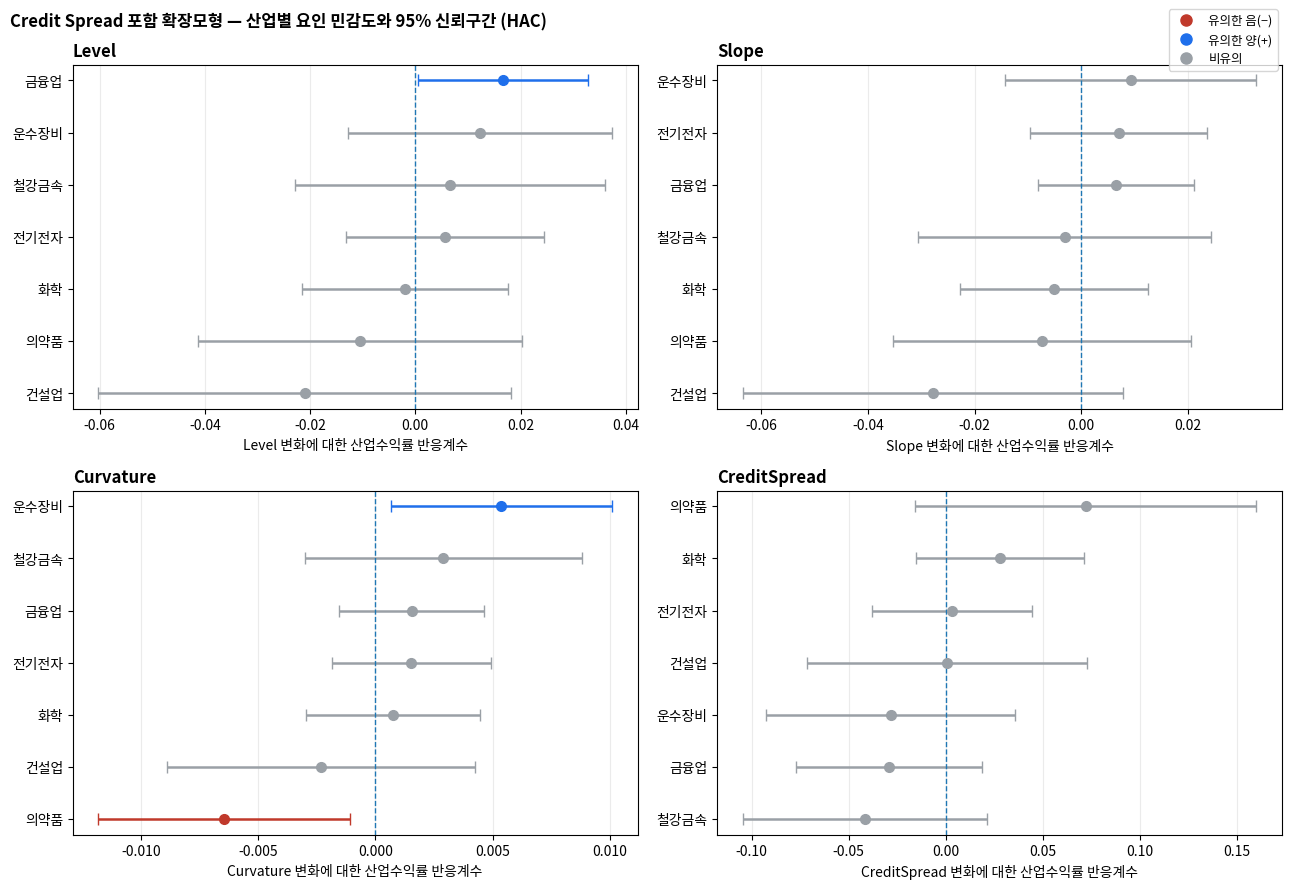

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/04_yield_curve_factor_ci.png


In [24]:
# 확장모형(4요인) 계수와 95% 신뢰구간을 2x2 패널로 그린다.
# 스타일(errorbar, capsize, 0선, 정렬)은 12단계 그림과 동일하게 유지한다.
credit_factor_order = ["Level", "Slope", "Curvature", "CreditSpread"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, factor in zip(axes.ravel(), credit_factor_order):
    plot_data = (
        credit_spread_extended[credit_spread_extended["factor"] == factor]
        .sort_values("coefficient")
        .reset_index(drop=True)
    )

    y_pos = np.arange(len(plot_data))

    lower_error = plot_data["coefficient"] - plot_data["ci_lower_95"]
    upper_error = plot_data["ci_upper_95"] - plot_data["coefficient"]

    # 부호 색상 규칙(STYLE_GUIDE §12): 유의 판정은 p_value < 0.05(significant_5pct) 기준.
    point_colors = [
        config.sign_color(coef, sig)
        for coef, sig in zip(plot_data["coefficient"], plot_data["significant_5pct"])
    ]

    for y, coef, lo, hi, color in zip(
        y_pos, plot_data["coefficient"], lower_error, upper_error, point_colors,
    ):
        ax.errorbar(
            coef, y,
            xerr=[[lo], [hi]],
            fmt="o",
            capsize=4,
            linewidth=1.8,
            markersize=7,
            color=color,
            ecolor=color,
        )

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_data["industry"])
    ax.set_xlabel(f"{factor} 변화에 대한 산업수익률 반응계수")
    ax.set_title(f"{factor}", loc="left", fontweight="bold")
    ax.grid(axis="x", alpha=0.25)

legend_handles = [
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
    Line2D([0], [0], marker="o", linestyle="None", markersize=8,
           color=config.SIGN_COLORS["ns"], label="비유의"),
]
fig.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=9,
           bbox_to_anchor=(0.99, 0.99))

fig.suptitle(
    "Credit Spread 포함 확장모형 — 산업별 요인 민감도와 95% 신뢰구간 (HAC)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()

credit_fig_path = config.H1_FIGDIR / "04_yield_curve_factor_ci.png"
fig.savefig(credit_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", credit_fig_path)


## 17단계. 강건성 판정

B-1의 3요인 결과와 확장모형 결과를 요인·산업별로 맞대어,
**부호가 유지되고 유의성 판정이 뒤집히지 않는지**를 확인한다.
눈으로 비교하면 놓치기 쉬우므로 표로 만든다.


In [25]:
# B-1 3요인 결과와 확장모형 결과를 요인·산업 단위로 비교한다.
# 파일을 다시 읽지 않고 메모리의 yield_curve_factor_betas 를 쓴다(덮어쓰기 방지).
robustness_check = (
    yield_curve_factor_betas[
        ["industry", "factor", "coefficient", "p_value", "significant_5pct"]
    ]
    .rename(columns={
        "coefficient": "coef_base",
        "p_value": "p_base",
        "significant_5pct": "sig_base",
    })
    .merge(
        credit_spread_extended[
            ["industry", "factor", "coefficient", "p_value", "significant_5pct"]
        ].rename(columns={
            "coefficient": "coef_ext",
            "p_value": "p_ext",
            "significant_5pct": "sig_ext",
        }),
        on=["industry", "factor"],
        how="inner",
        validate="one_to_one",
    )
)

robustness_check["sign_kept"] = (
    np.sign(robustness_check["coef_base"]) == np.sign(robustness_check["coef_ext"])
)
robustness_check["sig_kept"] = (
    robustness_check["sig_base"] == robustness_check["sig_ext"]
)

n_pairs = len(robustness_check)

print(f"비교 대상: {n_pairs}개 (산업 x 요인)")
print("부호 유지:", int(robustness_check["sign_kept"].sum()), "/", n_pairs)
print("유의성 판정 유지:", int(robustness_check["sig_kept"].sum()), "/", n_pairs)
print()
print("판정이 달라진 조합:")
display(
    robustness_check[
        ~robustness_check["sign_kept"] | ~robustness_check["sig_kept"]
    ].round(6)
)


비교 대상: 21개 (산업 x 요인)
부호 유지: 20 / 21
유의성 판정 유지: 21 / 21

판정이 달라진 조합:


,industry,factor,coef_base,p_base,sig_base,coef_ext,p_ext,sig_ext,sign_kept,sig_kept
20,화학,Curvature,-0.00008,0.962436,False,0.000758,0.68809,False,False,True


## 18단계. 요약 문서

분석 결과를 문장으로 옮긴 문서는 `results/H1_yield_curve/summary.md`다.
이 노트북이 만드는 산출물이 아니라 사람이 작성하는 문서이므로 코드 셀이 없다.

작성 기준은 `docs/STYLE_GUIDE.md`를 따른다.

- 금융업 Credit Spread 계수는 결과와 무관하게 **사전 예상 없음**으로 기술한다.
- BH 보정의 검정족 단위를 문서에 밝힌다.
- VIF는 Credit Spread뿐 아니라 기존 3요인도 함께 보고한다.
- 확증 분석과 사후 분석의 경계를 문서에서 구분한다.



# 최종 완료 확인

## 필수 산출물 확인

### B-1 (수익률곡선 핵심모형)

- `06_yield_curve_exposure.ipynb`
- `data/processed/industry_rate_panel_extended.csv`
- `results/H1_yield_curve/tables/maturity_beta_comparison.csv`
- `results/H1_yield_curve/tables/yield_curve_factor_betas.csv`

### B-2 (신용스프레드·검증·시각화)

- `results/H1_yield_curve/tables/credit_spread_betas.csv`
- `results/H1_yield_curve/tables/factor_correlation_vif.csv`
- `results/H1_yield_curve/figures/04_yield_curve_factor_ci.png`
- `results/H1_yield_curve/summary.md`

> 저장 경로는 저장소 재구성 이후 `results/H1_yield_curve/` 이다.
> 회의록(2026-07-16)의 `results/Yield_Curve/` 는 재구성 이전 표기다.
> 노트북 안에서는 경로를 문자열로 쓰지 않고 `config.H1_TABDIR` / `config.H1_FIGDIR` 를 쓴다.

## 최종 연구질문

> 산업은 금리 전반의 수준, 장단기 기울기, 중기 구간의 곡률 중 어떤 변화에 더 민감하게 반응하는가?

---

## 부록 — 탐색적 분석 (PART D)

아래 PART D는 **탐색적 분석(Exploratory)** 이며 B-1/B-2의 확정 결과가 아니다.
기존 산출물은 하나도 수정하지 않고, `exploratory_` 접두가 붙은 새 파일만 생성한다.

- `results/H1_yield_curve/tables/exploratory_joint_ftest.csv`
- `results/H1_yield_curve/tables/exploratory_two_factor_betas.csv`
- `results/H1_yield_curve/tables/exploratory_orthogonalized_betas.csv`
- `results/H1_yield_curve/figures/05_joint_ftest.png`
- `results/H1_yield_curve/figures/06_two_factor_ci.png`
- `results/H1_yield_curve/figures/07_orthogonalized_ci.png`


# PART D. 자료 구조 진단과 강건성 점검

> 본분석(PART A~C) 결과를 뒷받침하는 보조 분석이다.
> 산출물은 `exploratory_` 접두를 붙여 본분석 결과와 구분한다.

## 왜 이 분석을 하나

PART B에서 **곡률(Curvature)에서만** 산업별 차이가 유의하게 나타났다.

| 요인 | BH 유의 산업 | 산업 간 차이 검정 (BH p) |
|---|---|---|
| Level | 0개 | 0.2755 |
| Slope | 0개 | 0.2844 |
| **Curvature** | **2개** (의약품·운수장비) | **0.0047** |

왜 곡률에서만 나오는가? 15단계 VIF를 보면 답이 보인다.
Level(7.25)·Slope(7.01)는 서로 상관 −0.843으로 얽혀 있는 반면
**Curvature는 VIF 2.45로 깨끗하게 분리**된다.

즉 **요인이 분리되는 곳에서만 산업별 차이를 볼 수 있다.**

아래에서 네 가지를 확인한다.

1. **주성분분석** — 곡선 변동이 실제로 몇 차원인가
2. **동시검정** — 세 요인을 묶으면 어느 산업이 유의한가
3. **2요인·직교화** — 요인 구성을 바꾸면 결과가 어떻게 되는가
4. **산업 간 차이 검정 · HAC 시차** — 결론이 설정에 흔들리는가

## D-0. 수익률곡선은 몇 차원인가 — 주성분분석

### 왜 이것부터 보나

D-1 이후의 진단은 모두 "요인들이 서로 겹친다"를 전제로 한다.
그런데 **왜** 겹치는지는 아직 확인하지 않았다.

가능성은 둘이다.

1. 관측치나 만기가 부족해 요인 추정이 불안정하다 → **자료 부족 문제**
2. 한국 국고채가 실제로 한 방향으로만 움직인다 → **시장의 구조적 특성**

둘은 대응이 완전히 다르다. 1이면 자료를 더 모아야 하고,
2라면 애초에 나눌 것이 없으므로 **분해하지 않는 것이 옳은 선택**이 된다.

주성분분석(PCA)으로 구분한다. 네 만기 금리 변화의 공분산행렬을 고유분해해
각 성분이 전체 변동의 몇 %를 설명하는지 본다.

### 무엇을 보면 되나

- **PC1 설명비중이 압도적이고 적재값 부호가 모두 같으면** → 곡선이 평행이동으로 움직인다
- PC2·PC3 비중이 작으면 → 기울기·곡률 변동이 애초에 희소하다

이 분석은 모형을 추정하는 것이 아니라 **자료의 성질을 기술**하는 것이므로,
연구자 자유도가 개입하지 않는다. 다만 B-1 결과를 본 뒤 수행했다는 점은 밝혀 둔다.


In [26]:
# 국고채 1·3·5·10년 '변화분'의 주성분분석.
# 수준이 아니라 변화분을 쓰는 이유는 회귀에서 쓰는 변수가 변화분이기 때문이다.
YIELD_CHANGE_COLS = ["d_y1", "d_y3_new", "d_y5", "d_y10_new"]
MATURITY_LABELS = ["1년", "3년", "5년", "10년"]

# 설명변수는 모든 산업이 공유하므로 날짜 단위로 한 번씩만 쓴다.
yield_changes = (
    extended_panel[["date"] + YIELD_CHANGE_COLS]
    .drop_duplicates(subset="date")
    .dropna()
    .sort_values("date")
    .reset_index(drop=True)
)

Z = yield_changes[YIELD_CHANGE_COLS].to_numpy(dtype=float)
Z_centered = Z - Z.mean(axis=0)

# 공분산행렬 고유분해. eigh 는 오름차순이므로 뒤집어 내림차순으로 만든다.
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(Z_centered, rowvar=False))
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

explained = eigenvalues / eigenvalues.sum()

yield_pca = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(eigenvalues))],
    "eigenvalue": eigenvalues,
    "explained_ratio": explained,
    "cumulative_ratio": np.cumsum(explained),
})

# 각 만기가 성분에 얼마나 실리는지(적재값)를 같은 표에 붙인다.
for j, label in enumerate(MATURITY_LABELS):
    yield_pca[f"loading_{label}"] = eigenvectors[j, :]

# 부호는 고유벡터에서 임의로 결정되므로, PC1 이 양(+)이 되도록 통일한다.
for i in range(len(eigenvalues)):
    load = eigenvectors[:, i]
    if load.sum() < 0 if i == 0 else load[0] < 0:
        for j, label in enumerate(MATURITY_LABELS):
            yield_pca.loc[i, f"loading_{label}"] *= -1

yield_pca["n_obs"] = len(yield_changes)

pca_path = config.H1_TABDIR / "exploratory_yield_pca.csv"
yield_pca.to_csv(pca_path, index=False, encoding="utf-8-sig")

print("저장 완료:", pca_path)
print(f"PC1 설명비중: {explained[0]*100:.2f}%   PC1+PC2: {explained[:2].sum()*100:.2f}%")
display(yield_pca.round(5))


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_yield_pca.csv
PC1 설명비중: 92.09%   PC1+PC2: 96.88%


,component,eigenvalue,explained_ratio,cumulative_ratio,loading_1년,loading_3년,loading_5년,loading_10년,n_obs
0,PC1,0.00492,0.92086,0.92086,0.23634,0.53339,0.58489,0.56352,2451
1,PC2,0.00026,0.04795,0.96881,0.45814,0.53572,0.00965,-0.70923,2451
2,PC3,0.00012,0.02239,0.99120,0.85263,-0.38260,-0.24462,0.25845,2451
3,PC4,0.00005,0.00880,1.00000,0.08525,-0.53115,0.77329,-0.33562,2451


### 요인을 늘리면 설명력이 실제로 늘어나는가

PCA가 "곡선은 사실상 1차원"이라고 말한다면,
요인을 3개로 늘려도 산업수익률 설명력은 늘지 않아야 한다.

같은 산업·같은 기간에서 두 모형의 **조정 결정계수(adj R²)** 를 비교한다.
조정 결정계수를 쓰는 이유는 설명변수를 늘리면 일반 R²는 반드시 증가하기 때문이다.

- 모형 1: `KOSPI + d_y3` (설명변수 2개)
- 모형 2: `KOSPI + Level + Slope + Curvature` (설명변수 4개)


In [27]:
def compare_model_parsimony(data, base_vars, full_vars, control="kospi_return"):
    """단순모형과 확장모형의 조정 결정계수를 산업별로 비교한다."""
    rows = []

    for industry, group in data.groupby("industry"):
        need = ["industry_return", control] + list(base_vars) + list(full_vars)
        d = group[list(dict.fromkeys(need))].dropna()
        y = d["industry_return"]

        m_base = sm.OLS(y, sm.add_constant(d[[control] + list(base_vars)],
                                           has_constant="add")).fit()
        m_full = sm.OLS(y, sm.add_constant(d[[control] + list(full_vars)],
                                           has_constant="add")).fit()

        rows.append({
            "industry": industry,
            "adj_r2_single_rate": m_base.rsquared_adj,
            "adj_r2_three_factor": m_full.rsquared_adj,
            "delta_adj_r2": m_full.rsquared_adj - m_base.rsquared_adj,
            "improved": bool(m_full.rsquared_adj > m_base.rsquared_adj),
            "n_obs": int(m_base.nobs),
        })

    return pd.DataFrame(rows).sort_values("delta_adj_r2", ascending=False).reset_index(drop=True)


model_parsimony = compare_model_parsimony(
    extended_panel,
    base_vars=["d_y3"],
    full_vars=["d_ns_level", "d_ns_slope", "d_ns_curvature"],
)

parsimony_path = config.H1_TABDIR / "exploratory_model_parsimony.csv"
model_parsimony.to_csv(parsimony_path, index=False, encoding="utf-8-sig")

print("저장 완료:", parsimony_path)
print("설명력이 개선된 산업:", int(model_parsimony["improved"].sum()), "/ 7")
print("평균 조정 R² 증가폭:", round(model_parsimony["delta_adj_r2"].mean(), 6))
display(model_parsimony.round(6))


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_model_parsimony.csv
설명력이 개선된 산업: 2 / 7
평균 조정 R² 증가폭: -2.7e-05


,industry,adj_r2_single_rate,adj_r2_three_factor,delta_adj_r2,improved,n_obs
0,건설업,0.397745,0.398449,0.000704,True,2451
1,금융업,0.622556,0.622855,0.000299,True,2451
2,운수장비,0.471529,0.471458,-0.000071,False,2451
3,전기전자,0.719054,0.718931,-0.000122,False,2451
4,화학,0.643351,0.643162,-0.000189,False,2451
5,의약품,0.242638,0.242288,-0.000349,False,2451
6,철강금속,0.382919,0.382460,-0.000459,False,2451


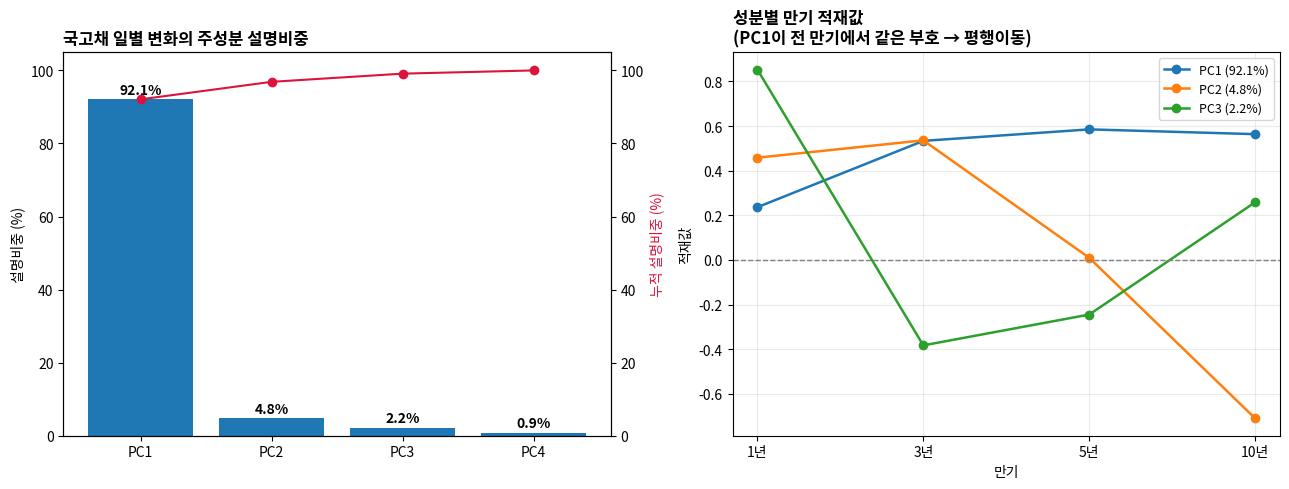

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/08_yield_curve_pca.png


In [28]:
# 왼쪽: 각 주성분의 설명비중과 누적선
# 오른쪽: 성분별 적재값. PC1 이 네 만기에서 같은 부호면 '평행이동'이다.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
x_pos = np.arange(len(yield_pca))
ax.bar(x_pos, yield_pca["explained_ratio"] * 100)
for i, v in enumerate(yield_pca["explained_ratio"] * 100):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")

ax_cum = ax.twinx()
ax_cum.plot(x_pos, yield_pca["cumulative_ratio"] * 100,
            marker="o", linewidth=1.5, color="crimson")
ax_cum.set_ylim(0, 105)
ax_cum.set_ylabel("누적 설명비중 (%)", color="crimson")

ax.set_xticks(x_pos)
ax.set_xticklabels(yield_pca["component"])
ax.set_ylim(0, 105)
ax.set_ylabel("설명비중 (%)")
ax.set_title("국고채 일별 변화의 주성분 설명비중", loc="left", fontweight="bold")

ax = axes[1]
for i in range(3):
    ax.plot(MATURITY_LABELS,
            [yield_pca.loc[i, f"loading_{m}"] for m in MATURITY_LABELS],
            marker="o", linewidth=1.8,
            label=f"PC{i+1} ({yield_pca.loc[i, 'explained_ratio']*100:.1f}%)")

ax.axhline(0, linestyle="--", linewidth=1, color="gray")
ax.set_xlabel("만기")
ax.set_ylabel("적재값")
ax.set_title("성분별 만기 적재값\n(PC1이 전 만기에서 같은 부호 → 평행이동)",
             loc="left", fontweight="bold")
ax.legend(fontsize=9)
ax.grid(alpha=0.25)

fig.tight_layout()

pca_fig_path = config.H1_FIGDIR / "08_yield_curve_pca.png"
fig.savefig(pca_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", pca_fig_path)


In [29]:
# 3년물이 곡선의 지배적 변동(PC1)을 얼마나 잘 대표하는지 확인한다.
# 상관이 높다면 '3년물 하나만 쓴 것'은 임의 선택이 아니라 효율적 선택이 된다.
pc1_score = Z_centered @ eigenvectors[:, 0]

proxy_check = pd.DataFrame({
    "date": yield_changes["date"],
    "pc1": pc1_score,
}).merge(
    extended_panel[["date", "d_y3", "d_ns_level", "d_ns_slope", "d_ns_curvature"]]
    .drop_duplicates(subset="date"),
    on="date",
    how="inner",
)

pc1_corr = (
    proxy_check[["pc1", "d_y3", "d_ns_level", "d_ns_slope", "d_ns_curvature"]]
    .corr()["pc1"]
    .drop("pc1")
    .abs()
    .sort_values(ascending=False)
    .rename("abs_corr_with_pc1")
    .reset_index()
    .rename(columns={"index": "variable"})
)

print("PC1(지배적 곡선변동)과의 절대상관 — 높을수록 좋은 대리변수")
display(pc1_corr.round(4))


PC1(지배적 곡선변동)과의 절대상관 — 높을수록 좋은 대리변수


,variable,abs_corr_with_pc1
0,d_y3,0.9647
1,d_ns_slope,0.7197
2,d_ns_level,0.6036
3,d_ns_curvature,0.6030


## D-1. Joint Significance Test (F-test)

### 무엇을 검정하나

$$
H_0:\ \beta_{Level}=\beta_{Slope}=\beta_{Curvature}=0
$$

"수익률곡선이 이 산업 수익률과 **아무 관계도 없다**"가 귀무가설이다.

개별 t검정은 "다른 두 요인을 통제한 뒤 이 요인 **하나만**의 고유 기여"를 묻는다.
요인들이 겹쳐 있으면 고유 기여는 작아져 개별 t는 죽지만,
**셋이 함께 설명하는 몫**은 그대로 남는다.

따라서 다음 조합이 나오면 다중공선성의 전형적 증상이다.

> 동시검정 유의 + 개별검정 전부 비유의

표준오차는 HAC(maxlags=5)를 유지하므로 F검정도 HAC 기반 Wald 검정이 된다.
7개 산업 다중검정이므로 PART C에서 만든 `add_bh_correction()`을 그대로 쓴다.


In [30]:
def run_joint_significance_test(data, hac_lags=5,
                                test_vars=("d_ns_level", "d_ns_slope", "d_ns_curvature"),
                                control_cols=("kospi_return",)):
    """산업별로 H0: 지정한 요인 계수가 모두 0 인지 동시검정(F-test)한다."""
    test_vars = list(test_vars)
    x_cols = list(control_cols) + test_vars

    rows = []

    for industry, group in data.groupby("industry"):
        reg_data = group[["industry_return"] + x_cols].dropna()

        X = sm.add_constant(reg_data[x_cols], has_constant="add")
        y = reg_data["industry_return"]

        model = sm.OLS(y, X).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": hac_lags},
        )

        # "d_ns_level = 0, d_ns_slope = 0, ..." 형태의 제약식을 만든다.
        hypothesis = ", ".join(f"{v} = 0" for v in test_vars)
        f_test = model.f_test(hypothesis)

        individual_p = model.pvalues[test_vars]

        rows.append({
            "industry": industry,
            "model": "Exploratory_Joint_3Factor",
            "joint_f_stat": float(f_test.fvalue),
            "joint_p_value": float(f_test.pvalue),
            "df_num": int(len(test_vars)),
            "df_denom": int(model.df_resid),
            "min_individual_p": float(individual_p.min()),
            "n_individual_sig_5pct": int((individual_p < 0.05).sum()),
            "joint_sig_5pct": bool(f_test.pvalue < 0.05),
            "r_squared": model.rsquared,
            "adj_r_squared": model.rsquared_adj,
            "n_obs": int(model.nobs),
            "hac_lags": hac_lags,
        })

    return pd.DataFrame(rows)


joint_ftest = (
    run_joint_significance_test(extended_panel, hac_lags=HAC_LAGS)
    .pipe(add_bh_correction, group_cols=("model",), p_col="joint_p_value")
    .rename(columns={"p_value_bh": "joint_p_value_bh"})
    .sort_values("joint_p_value")
    .reset_index(drop=True)
)

joint_path = config.H1_TABDIR / "exploratory_joint_ftest.csv"
joint_ftest.to_csv(joint_path, index=False, encoding="utf-8-sig")

print("저장 완료:", joint_path)
print("동시검정 유의 산업:", int(joint_ftest["joint_sig_5pct"].sum()), "/ 7")
print("개별검정 유의 조합:", int(joint_ftest["n_individual_sig_5pct"].sum()), "/ 21")
display(joint_ftest.round(5))


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_joint_ftest.csv
동시검정 유의 산업: 3 / 7
개별검정 유의 조합: 3 / 21


,industry,model,joint_f_stat,joint_p_value,df_num,df_denom,min_individual_p,n_individual_sig_5pct,joint_sig_5pct,r_squared,adj_r_squared,n_obs,hac_lags,joint_p_value_bh,bh_n_tests,bh_family,significant_5pct_bh
0,의약품,Exploratory_Joint_3Factor,4.73722,0.00268,3,2446,0.00236,1,True,0.24353,0.24229,2451,5,0.01875,7,Exploratory_Joint_3Factor,True
1,운수장비,Exploratory_Joint_3Factor,3.59193,0.01313,3,2446,0.00721,1,True,0.47232,0.47146,2451,5,0.04596,7,Exploratory_Joint_3Factor,True
2,금융업,Exploratory_Joint_3Factor,2.97331,0.03057,3,2446,0.02938,1,True,0.62347,0.62286,2451,5,0.07134,7,Exploratory_Joint_3Factor,False
3,철강금속,Exploratory_Joint_3Factor,2.03121,0.10744,3,2446,0.14948,0,False,0.38347,0.38246,2451,5,0.18802,7,Exploratory_Joint_3Factor,False
4,건설업,Exploratory_Joint_3Factor,1.25128,0.28955,3,2446,0.12431,0,False,0.39943,0.39845,2451,5,0.40537,7,Exploratory_Joint_3Factor,False
5,전기전자,Exploratory_Joint_3Factor,0.38846,0.76133,3,2446,0.36228,0,False,0.71939,0.71893,2451,5,0.79026,7,Exploratory_Joint_3Factor,False
6,화학,Exploratory_Joint_3Factor,0.34849,0.79026,3,2446,0.51630,0,False,0.64374,0.64316,2451,5,0.79026,7,Exploratory_Joint_3Factor,False


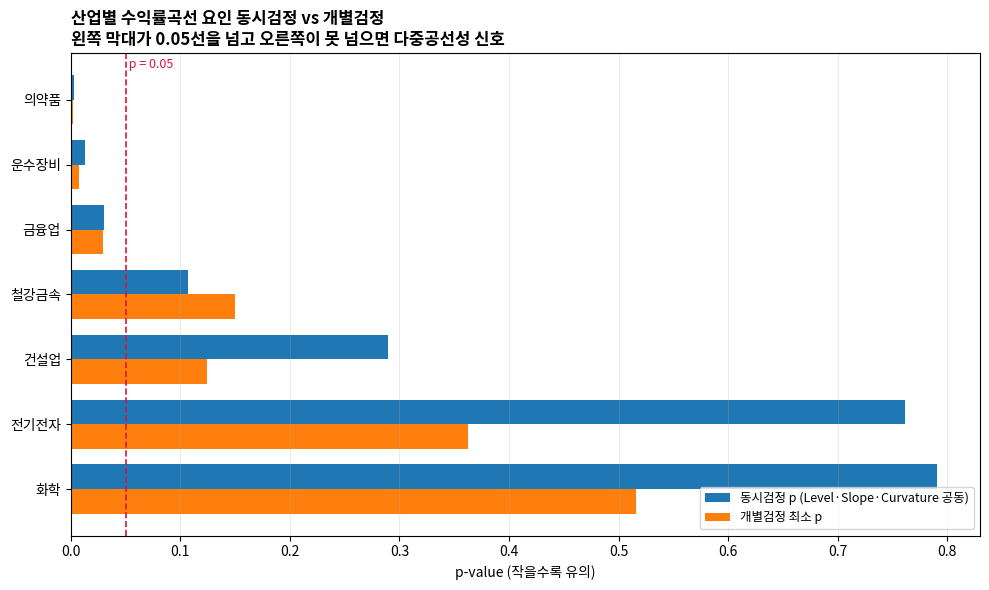

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/05_joint_ftest.png


In [31]:
# 동시검정 p값과 개별검정 최소 p값을 나란히 놓아
# "함께는 유의한데 따로는 아니다"가 눈에 보이게 한다.
plot_data = joint_ftest.sort_values("joint_p_value", ascending=False).reset_index(drop=True)

y_pos = np.arange(len(plot_data))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(y_pos + bar_height / 2, plot_data["joint_p_value"],
        height=bar_height, label="동시검정 p (Level·Slope·Curvature 공동)")
ax.barh(y_pos - bar_height / 2, plot_data["min_individual_p"],
        height=bar_height, label="개별검정 최소 p")

ax.axvline(0.05, linestyle="--", linewidth=1.2, color="crimson")
ax.text(0.05, len(plot_data) - 0.35, " p = 0.05", color="crimson", fontsize=9, va="top")

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["industry"])
ax.set_xlabel("p-value (작을수록 유의)")
ax.set_title(
    "산업별 수익률곡선 요인 동시검정 vs 개별검정\n"
    "왼쪽 막대가 0.05선을 넘고 오른쪽이 못 넘으면 다중공선성 신호",
    loc="left",
    fontweight="bold",
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

joint_fig_path = config.H1_FIGDIR / "05_joint_ftest.png"
fig.savefig(joint_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", joint_fig_path)


## D-2. 2요인 모형 (Level + Slope)

### 왜 Curvature를 빼나

본분석에서 유의한 결과는 전부 Curvature에서 나왔다.
그렇다면 **Curvature를 빼면 Level·Slope가 그 자리를 대신하는지**를 확인해야 한다.

Level–Slope 상관이 **−0.843**으로 강하므로, 셋 중 하나를 빼면
남은 둘의 VIF는 크게 떨어진다(설명변수가 2개일 때 VIF는 $1/(1-r^2)$).

### 무엇을 확인하나

Curvature를 제거해 겹침을 줄였을 때 **Level·Slope가 유의해지는가.**
유의해지지 않는다면, 곡률에서 나온 결과는 단순히 "요인을 줄여서 생긴 것"이 아니라는 뜻이다.

9단계의 `run_yield_curve_factor_model()`을 `x_cols`만 바꿔 그대로 재사용한다.

In [32]:
# Level + Slope 2요인 모형. 함수는 9단계 것을 그대로 쓴다.
TWO_FACTOR_X_COLS = ["kospi_return", "d_ns_level", "d_ns_slope"]
TWO_FACTOR_LABELS = {"d_ns_level": "Level", "d_ns_slope": "Slope"}

two_factor_betas = (
    run_yield_curve_factor_model(
        extended_panel,
        hac_lags=HAC_LAGS,
        x_cols=TWO_FACTOR_X_COLS,
        factor_labels=TWO_FACTOR_LABELS,
    )
    .assign(model="Exploratory_TwoFactor")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

# 2요인 모형의 VIF 를 다시 계산한다(설명변수가 줄면 VIF 도 줄어야 한다).
two_factor_daily = (
    extended_panel[["date"] + TWO_FACTOR_X_COLS]
    .drop_duplicates(subset="date")
    .dropna()
)
two_factor_design = sm.add_constant(two_factor_daily[TWO_FACTOR_X_COLS], has_constant="add")

two_factor_vif = {
    var: variance_inflation_factor(two_factor_design.to_numpy(dtype=float), i)
    for i, var in enumerate(two_factor_design.columns)
    if var != "const"
}

two_factor_betas["vif"] = two_factor_betas["variable"].map(two_factor_vif)

two_factor_path = config.H1_TABDIR / "exploratory_two_factor_betas.csv"
two_factor_betas.to_csv(two_factor_path, index=False, encoding="utf-8-sig")

print("저장 완료:", two_factor_path)
print("2요인 VIF:", {k: round(v, 3) for k, v in two_factor_vif.items()})
print("3요인 대비 유의 조합:",
      int(two_factor_betas["significant_5pct"].sum()), "/", len(two_factor_betas))
display(two_factor_betas.round(5))


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_two_factor_betas.csv
2요인 VIF: {'kospi_return': np.float64(1.0), 'd_ns_level': np.float64(3.455), 'd_ns_slope': np.float64(3.454)}
3요인 대비 유의 조합: 1 / 14


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,...,adj_r_squared,n_obs,hac_lags,optimal_lambda,model,p_value_bh,bh_n_tests,bh_family,significant_5pct_bh,vif
0,건설업,Level,d_ns_level,-0.01153,0.01257,-0.91767,0.35879,-0.03616,0.01310,False,...,0.39852,2451,5,0.5,Exploratory_TwoFactor,0.54582,7,Exploratory_TwoFactor | Level,False,3.45470
1,건설업,Slope,d_ns_slope,-0.01900,0.01190,-1.59641,0.11040,-0.04233,0.00433,False,...,0.39852,2451,5,0.5,Exploratory_TwoFactor,0.19319,7,Exploratory_TwoFactor | Slope,False,3.45399
2,금융업,Level,d_ns_level,0.00817,0.00637,1.28217,0.19978,-0.00432,0.02065,False,...,0.62265,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
3,금융업,Slope,d_ns_slope,-0.00190,0.00532,-0.35701,0.72109,-0.01232,0.00853,False,...,0.62265,2451,5,0.5,Exploratory_TwoFactor,0.78542,7,Exploratory_TwoFactor | Slope,False,3.45399
4,운수장비,Level,d_ns_level,-0.01166,0.00901,-1.29442,0.19552,-0.02932,0.00600,False,...,0.47014,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
5,운수장비,Slope,d_ns_slope,-0.01346,0.00812,-1.65867,0.09718,-0.02937,0.00245,False,...,0.47014,2451,5,0.5,Exploratory_TwoFactor,0.19319,7,Exploratory_TwoFactor | Slope,False,3.45399
6,의약품,Level,d_ns_level,0.02115,0.01156,1.83028,0.06721,-0.00150,0.04380,False,...,0.24022,2451,5,0.5,Exploratory_TwoFactor,0.46616,7,Exploratory_TwoFactor | Level,False,3.45470
7,의약품,Slope,d_ns_slope,0.02338,0.00983,2.37760,0.01743,0.00411,0.04265,True,...,0.24022,2451,5,0.5,Exploratory_TwoFactor,0.12198,7,Exploratory_TwoFactor | Slope,False,3.45399
8,전기전자,Level,d_ns_level,-0.00037,0.00638,-0.05864,0.95324,-0.01288,0.01213,False,...,0.71896,2451,5,0.5,Exploratory_TwoFactor,0.95324,7,Exploratory_TwoFactor | Level,False,3.45470
9,전기전자,Slope,d_ns_slope,0.00153,0.00561,0.27226,0.78542,-0.00947,0.01252,False,...,0.71896,2451,5,0.5,Exploratory_TwoFactor,0.78542,7,Exploratory_TwoFactor | Slope,False,3.45399


## D-3. 직교화 (Gram–Schmidt Orthogonalization)

### 방법

요인을 순서대로 쌓으면서 앞 요인과 겹치는 부분을 잔차로 제거한다.

1. `o_level` = Level (그대로)
2. `o_slope` = Slope를 `o_level`에 회귀한 **잔차**
3. `o_curvature` = Curvature를 `o_level`·`o_slope`에 회귀한 **잔차**

이렇게 만든 세 변수는 서로 상관이 0이므로 VIF가 1이 된다.

### 먼저 알아야 할 한계 — 이건 해결책이 아니다

직교화는 겹치는 정보를 **없애는 것이 아니라 앞 요인에 몰아주는 것**이다.
따라서 결과는 **순서에 전적으로 의존**한다. Slope를 먼저 놓으면 답이 달라진다.

특히 FWL(Frisch–Waugh–Lovell) 정리에 의해
**마지막에 직교화한 Curvature의 계수와 표준오차는 원래 3요인 모형과 정확히 같다.**
아래 결과에서 이 점을 검증한다. 즉 직교화로 "유의성이 생겨난다면"
그건 새로운 정보가 아니라 공유된 변동을 앞 요인에 배정한 결과일 뿐이다.

그래서 이 분석은 **어느 요인이 공유 변동의 대부분을 설명하는지 진단하는 용도**이지,
논문 본문 결과로 쓸 수 있는 추정치가 아니다.


In [33]:
def orthogonalize_factors(daily, factor_cols):
    """Gram-Schmidt 직교화. 앞 요인과 겹치는 부분을 잔차로 떼어낸다."""
    out = daily.copy()
    built = []

    for col in factor_cols:
        target = f"o_{col}"
        if not built:
            out[target] = out[col]                      # 첫 요인은 그대로
        else:
            X = sm.add_constant(out[built], has_constant="add")
            out[target] = sm.OLS(out[col], X).fit().resid   # 앞 요인 성분 제거
        built.append(target)

    return out, built


BASE_FACTORS = ["d_ns_level", "d_ns_slope", "d_ns_curvature"]

# 설명변수는 모든 산업이 공유하므로 날짜 단위에서 한 번만 직교화한다.
orth_daily, ORTH_COLS = orthogonalize_factors(
    extended_panel[["date"] + BASE_FACTORS].drop_duplicates(subset="date").dropna(),
    BASE_FACTORS,
)

# 직교화 확인: 상관 0, VIF 1
print("직교화 후 상관행렬:")
display(orth_daily[ORTH_COLS].corr().round(6))

# 기존 패널은 건드리지 않고 사본에만 직교 변수를 붙인다.
exploratory_panel = extended_panel.merge(
    orth_daily[["date"] + ORTH_COLS],
    on="date",
    how="left",
    validate="many_to_one",
)

ORTH_X_COLS = ["kospi_return"] + ORTH_COLS
ORTH_LABELS = {
    "o_d_ns_level": "Level_orth",
    "o_d_ns_slope": "Slope_orth",
    "o_d_ns_curvature": "Curvature_orth",
}

orthogonalized_betas = (
    run_yield_curve_factor_model(
        exploratory_panel,
        hac_lags=HAC_LAGS,
        x_cols=ORTH_X_COLS,
        factor_labels=ORTH_LABELS,
    )
    .assign(model="Exploratory_Orthogonalized")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

orth_path = config.H1_TABDIR / "exploratory_orthogonalized_betas.csv"
orthogonalized_betas.to_csv(orth_path, index=False, encoding="utf-8-sig")

print("저장 완료:", orth_path)
display(orthogonalized_betas.round(5))


직교화 후 상관행렬:


,o_d_ns_level,o_d_ns_slope,o_d_ns_curvature
o_d_ns_level,1.0,-0.0,0.0
o_d_ns_slope,-0.0,1.0,-0.0
o_d_ns_curvature,0.0,-0.0,1.0


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_orthogonalized_betas.csv


,industry,factor,variable,coefficient,std_error_hac,t_value,p_value,ci_lower_95,ci_upper_95,significant_5pct,...,r_squared,adj_r_squared,n_obs,hac_lags,optimal_lambda,model,p_value_bh,bh_n_tests,bh_family,significant_5pct_bh
0,건설업,Level_orth,o_d_ns_level,0.00533,0.00637,0.83580,0.40327,-0.00717,0.01782,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.91886,7,Exploratory_Orthogonalized | Level_orth,False
1,건설업,Slope_orth,o_d_ns_slope,-0.01900,0.01198,-1.58630,0.11267,-0.04247,0.00447,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.19717,7,Exploratory_Orthogonalized | Slope_orth,False
2,건설업,Curvature_orth,o_d_ns_curvature,-0.00234,0.00306,-0.76450,0.44457,-0.00833,0.00366,False,...,0.39943,0.39845,2451,5,0.5,Exploratory_Orthogonalized,0.51866,7,Exploratory_Orthogonalized | Curvature_orth,False
3,금융업,Level_orth,o_d_ns_level,0.00984,0.00436,2.25534,0.02411,0.00129,0.01840,True,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.16878,7,Exploratory_Orthogonalized | Level_orth,False
4,금융업,Slope_orth,o_d_ns_slope,-0.00190,0.00533,-0.35725,0.72091,-0.01236,0.00855,False,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.78731,7,Exploratory_Orthogonalized | Slope_orth,False
5,금융업,Curvature_orth,o_d_ns_curvature,0.00241,0.00137,1.76201,0.07807,-0.00027,0.00510,False,...,0.62347,0.62286,2451,5,0.5,Exploratory_Orthogonalized,0.18216,7,Exploratory_Orthogonalized | Curvature_orth,False
6,운수장비,Level_orth,o_d_ns_level,0.00026,0.00557,0.04651,0.96290,-0.01066,0.01118,False,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.96290,7,Exploratory_Orthogonalized | Level_orth,False
7,운수장비,Slope_orth,o_d_ns_slope,-0.01348,0.00789,-1.70782,0.08767,-0.02895,0.00199,False,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.19717,7,Exploratory_Orthogonalized | Slope_orth,False
8,운수장비,Curvature_orth,o_d_ns_curvature,0.00621,0.00231,2.68719,0.00721,0.00168,0.01074,True,...,0.47232,0.47146,2451,5,0.5,Exploratory_Orthogonalized,0.02522,7,Exploratory_Orthogonalized | Curvature_orth,True
9,의약품,Level_orth,o_d_ns_level,0.00044,0.00826,0.05345,0.95737,-0.01574,0.01662,False,...,0.24353,0.24229,2451,5,0.5,Exploratory_Orthogonalized,0.96290,7,Exploratory_Orthogonalized | Level_orth,False


In [34]:
# FWL 검증 — 마지막에 직교화한 Curvature 는 원래 3요인 모형과 같아야 한다.
# 같지 않다면 직교화 구현이 틀린 것이므로 반드시 확인한다.
fwl_check = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient", "std_error_hac", "p_value"]]
    .rename(columns={
        "coefficient": "coef_3factor",
        "std_error_hac": "se_3factor",
        "p_value": "p_3factor",
    })
    .merge(
        orthogonalized_betas[orthogonalized_betas["factor"] == "Curvature_orth"]
        [["industry", "coefficient", "std_error_hac", "p_value"]]
        .rename(columns={
            "coefficient": "coef_orth",
            "std_error_hac": "se_orth",
            "p_value": "p_orth",
        }),
        on="industry",
        validate="one_to_one",
    )
)

fwl_check["max_abs_diff"] = np.maximum(
    (fwl_check["coef_3factor"] - fwl_check["coef_orth"]).abs(),
    (fwl_check["se_3factor"] - fwl_check["se_orth"]).abs(),
)

print("FWL 검증 — Curvature 계수·SE 최대 절대차:",
      f'{fwl_check["max_abs_diff"].max():.3e}')
print("(0에 가까워야 정상. 직교화가 마지막 요인 추정치를 바꾸지 않음을 확인)")
display(fwl_check.round(6))


FWL 검증 — Curvature 계수·SE 최대 절대차: 1.264e-16
(0에 가까워야 정상. 직교화가 마지막 요인 추정치를 바꾸지 않음을 확인)


,industry,coef_3factor,se_3factor,p_3factor,coef_orth,se_orth,p_orth,max_abs_diff
0,건설업,-0.002338,0.003058,0.444568,-0.002338,0.003058,0.444568,0.0
1,금융업,0.002413,0.001370,0.078067,0.002413,0.001370,0.078067,0.0
2,운수장비,0.006207,0.002310,0.007206,0.006207,0.002310,0.007206,0.0
3,의약품,-0.008599,0.002828,0.002363,-0.008599,0.002828,0.002363,0.0
4,전기전자,0.001441,0.001582,0.362277,0.001441,0.001582,0.362277,0.0
5,철강금속,0.004148,0.002878,0.149483,0.004148,0.002878,0.149483,0.0
6,화학,-0.000080,0.001704,0.962436,-0.000080,0.001704,0.962436,0.0


## D-4. 산업마다 다른가 — 산업 간 계수 동일성 검정

### 지금까지와 무엇이 다른가

지금까지 한 검정은 전부 **"이 산업의 계수가 0인가"** 였다.
그런데 이 연구의 질문은 **"산업마다 다른가"** 다. 둘은 다른 질문이다.

각 산업을 따로 검정하면 7번을 물어야 하고 다중검정 부담이 생긴다.
반면 산업 간 차이는 **한 번에** 검정할 수 있다.
개별 계수가 전부 비유의해도 산업 간 차이는 유의할 수 있다.

$$
H_0:\ \delta_1 = \delta_2 = \cdots = \delta_K
$$

### 검정 설정은 프로젝트 표준을 따른다

`src/models.py`의 `cross_industry_Ftest()` 사양을 그대로 쓴다.

- 산업더미로 **산업별 절편**
- 산업별 시장 교차항으로 **시장베타도 산업마다 다르게** (이걸 빠뜨리면 시장효과가 금리 교차항으로 샌다)
- **날짜 클러스터 표준오차** — 같은 날 산업 간 잔차 상관을 보정한다.
  시계열 HAC는 이 상관을 놓쳐 검정이 지나치게 보수적이 된다.

기존 함수와의 차이는 **요인을 여러 개 동시에 넣는다**는 점 하나다.
아래에서 3년물 하나만 넣어 기존 함수와 결과가 일치하는지 검증한다.


In [35]:
def run_industry_difference_test(data, test_vars, model_name,
                                 ret_col="industry_return",
                                 mkt_col="kospi_return",
                                 industry_col="industry",
                                 date_col="date"):
    """H0: 모든 산업의 계수가 같다. 요인별로 F-검정한다."""
    test_vars = list(test_vars)
    d = data.dropna(subset=[ret_col, mkt_col, industry_col, date_col] + test_vars).copy()

    date_codes = pd.factorize(d[date_col])[0]
    if len(np.unique(date_codes)) < 2:
        raise ValueError("날짜 그룹이 2개 이상이어야 클러스터 SE를 쓸 수 있습니다.")

    dummies = pd.get_dummies(d[industry_col], prefix="ind", dtype=float)
    blocks = [dummies, dummies.mul(d[mkt_col].values, axis=0).add_prefix("mkt_")]

    for v in test_vars:
        blocks.append(dummies.mul(d[v].values, axis=0).add_prefix(f"{v}__"))

    X = pd.concat(blocks, axis=1)
    names = list(X.columns)

    model = sm.OLS(d[ret_col].values, X.values).fit(
        cov_type="cluster", cov_kwds={"groups": date_codes})

    rows = []
    for v in test_vars:
        idx = [i for i, c in enumerate(names) if c.startswith(f"{v}__")]

        # "첫 산업 계수 = 나머지 산업 계수" 제약행렬
        R = np.zeros((len(idx) - 1, len(names)))
        for r, j in enumerate(idx[1:]):
            R[r, idx[0]] = 1.0
            R[r, j] = -1.0

        t = model.f_test(R)

        rows.append({
            "model": model_name,
            "variable": v,
            "f_stat": float(t.fvalue),
            "p_value": float(t.pvalue),
            "df_num": int(len(idx) - 1),
            "n_industries": int(dummies.shape[1]),
            "n_obs": int(model.nobs),
            "n_dates": int(len(np.unique(date_codes))),
            "significant_5pct": bool(t.pvalue < 0.05),
        })

    return pd.DataFrame(rows)


In [36]:
# ── 검증: 3년물 하나만 넣어 src/models.py 의 기존 함수와 결과가 같은지 확인한다.
from src.models import cross_industry_Ftest

_check_new = run_industry_difference_test(
    extended_panel, ["d_y3"], "검증용",
)

_check_old = cross_industry_Ftest(
    extended_panel
    .dropna(subset=["industry_return", "kospi_return", "d_y3", "date"])
    .rename(columns={"industry_return": "ret", "kospi_return": "mkt", "d_y3": "dY"})
    [["industry", "ret", "mkt", "dY", "date"]]
)

_diff_f = abs(_check_new.loc[0, "f_stat"] - float(_check_old.fvalue))
_diff_p = abs(_check_new.loc[0, "p_value"] - float(_check_old.pvalue))

print("[검증] 새 함수 vs src/models.py:cross_industry_Ftest()")
print(f"   F  차이: {_diff_f:.3e}")
print(f"   p  차이: {_diff_p:.3e}")

if max(_diff_f, _diff_p) > 1e-8:
    raise RuntimeError("기존 함수와 결과가 다릅니다. 설정을 다시 확인하세요.")

print("   → 일치. 새 함수는 기존 사양을 그대로 따른다.")


[검증] 새 함수 vs src/models.py:cross_industry_Ftest()
   F  차이: 0.000e+00
   p  차이: 0.000e+00
   → 일치. 새 함수는 기존 사양을 그대로 따른다.


In [37]:
# 3년물 단일 / 3요인 / 4요인 세 모형을 검정한다.
industry_difference_test = pd.concat([
    run_industry_difference_test(extended_panel, ["d_y3"], "A_Single_3Y"),
    run_industry_difference_test(
        extended_panel,
        ["d_ns_level", "d_ns_slope", "d_ns_curvature"],
        "B_ThreeFactor",
    ),
    run_industry_difference_test(
        extended_panel,
        ["d_ns_level", "d_ns_slope", "d_ns_curvature", "d_credit_spread"],
        "C_FourFactor",
    ),
], ignore_index=True)

FACTOR_NAME = {
    "d_y3": "3Y_Rate",
    "d_ns_level": "Level",
    "d_ns_slope": "Slope",
    "d_ns_curvature": "Curvature",
    "d_credit_spread": "CreditSpread",
}
industry_difference_test.insert(
    2, "factor", industry_difference_test["variable"].map(FACTOR_NAME)
)

# 검정족 = 한 모형 안의 요인들
industry_difference_test = add_bh_correction(
    industry_difference_test, group_cols=("model",), p_col="p_value"
)

diff_path = config.H1_TABDIR / "industry_difference_test.csv"
industry_difference_test.to_csv(diff_path, index=False, encoding="utf-8-sig")

print("저장 완료:", diff_path)
display(
    industry_difference_test[
        ["model", "factor", "f_stat", "df_num", "p_value",
         "p_value_bh", "significant_5pct", "significant_5pct_bh",
         "n_obs", "n_dates"]
    ].round(5)
)


저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/industry_difference_test.csv


,model,factor,f_stat,df_num,p_value,p_value_bh,significant_5pct,significant_5pct_bh,n_obs,n_dates
0,A_Single_3Y,3Y_Rate,4.18916,6,0.00034,0.00034,True,True,17157,2451
1,B_ThreeFactor,Level,1.47235,6,0.18364,0.27545,False,False,17157,2451
2,B_ThreeFactor,Slope,1.23634,6,0.28435,0.28435,False,False,17157,2451
3,B_ThreeFactor,Curvature,3.58002,6,0.00155,0.00466,True,True,17157,2451
4,C_FourFactor,Level,1.26717,6,0.26911,0.36993,False,False,17157,2451
5,C_FourFactor,Slope,1.14136,6,0.33550,0.36993,False,False,17157,2451
6,C_FourFactor,Curvature,2.12352,6,0.04773,0.19092,True,False,17157,2451
7,C_FourFactor,CreditSpread,1.08329,6,0.36993,0.36993,False,False,17157,2451


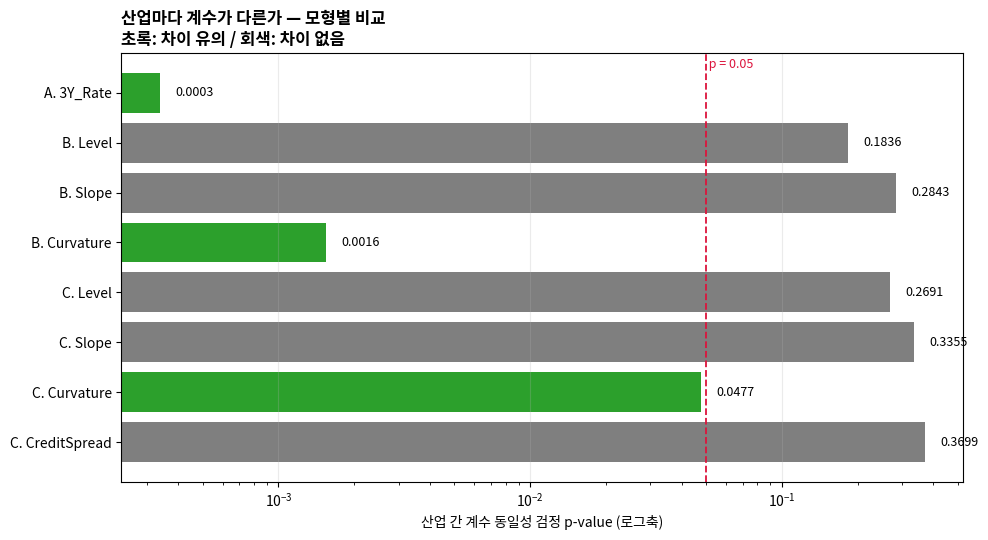

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/09_industry_difference_test.png


In [38]:
# 모형별 p값 비교. 0.05선을 넘는지가 핵심이라 로그축으로 그린다.
plot_data = industry_difference_test.copy()
plot_data["label"] = plot_data["model"].str[0] + ". " + plot_data["factor"]
plot_data = plot_data.iloc[::-1].reset_index(drop=True)

colors = ["tab:green" if s else "tab:gray" for s in plot_data["significant_5pct"]]

fig, ax = plt.subplots(figsize=(10, 5.5))

y_pos = np.arange(len(plot_data))
ax.barh(y_pos, plot_data["p_value"], color=colors)

for i, v in enumerate(plot_data["p_value"]):
    ax.text(v * 1.15, i, f"{v:.4f}", va="center", fontsize=9)

ax.axvline(0.05, linestyle="--", linewidth=1.3, color="crimson")
ax.text(0.05, len(plot_data) - 0.3, " p = 0.05", color="crimson", fontsize=9, va="top")

ax.set_xscale("log")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["label"])
ax.set_xlabel("산업 간 계수 동일성 검정 p-value (로그축)")
ax.set_title(
    "산업마다 계수가 다른가 — 모형별 비교\n"
    "초록: 차이 유의 / 회색: 차이 없음",
    loc="left",
    fontweight="bold",
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

diff_fig_path = config.H1_FIGDIR / "09_industry_difference_test.png"
fig.savefig(diff_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", diff_fig_path)


## D-5. 세 모형 비교와 그림

3요인 · 2요인 · 직교화 결과를 한자리에 놓고,
**어떤 모형에서 몇 개 조합이 유의해지는지**를 본다.

유의 개수가 늘어난다고 해서 그 모형이 '더 옳은' 것은 아니다.
같은 데이터에서 모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking이므로,
아래 표는 **어느 설정에서 신호가 살아나는지 진단하는 용도**로만 쓴다.


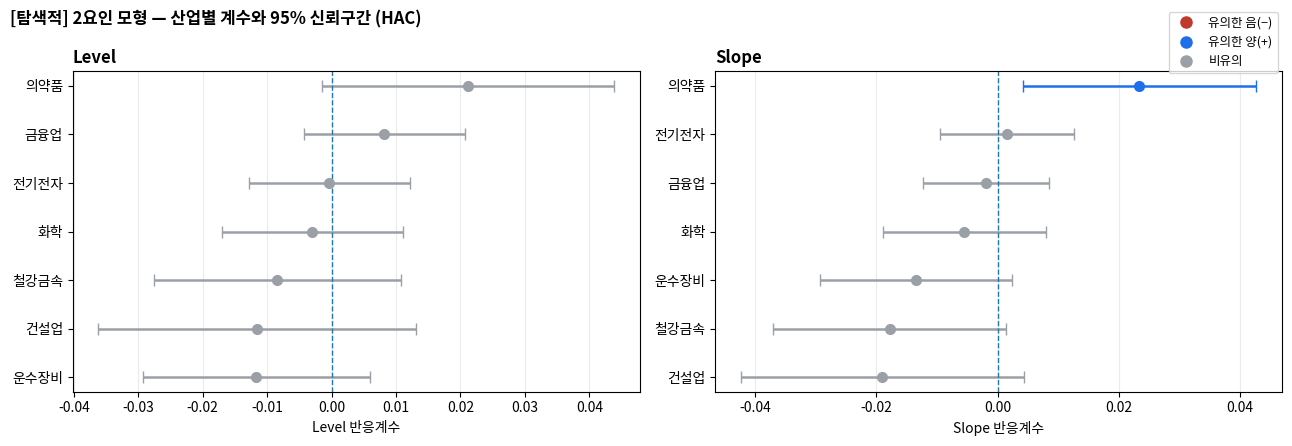

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/06_two_factor_ci.png


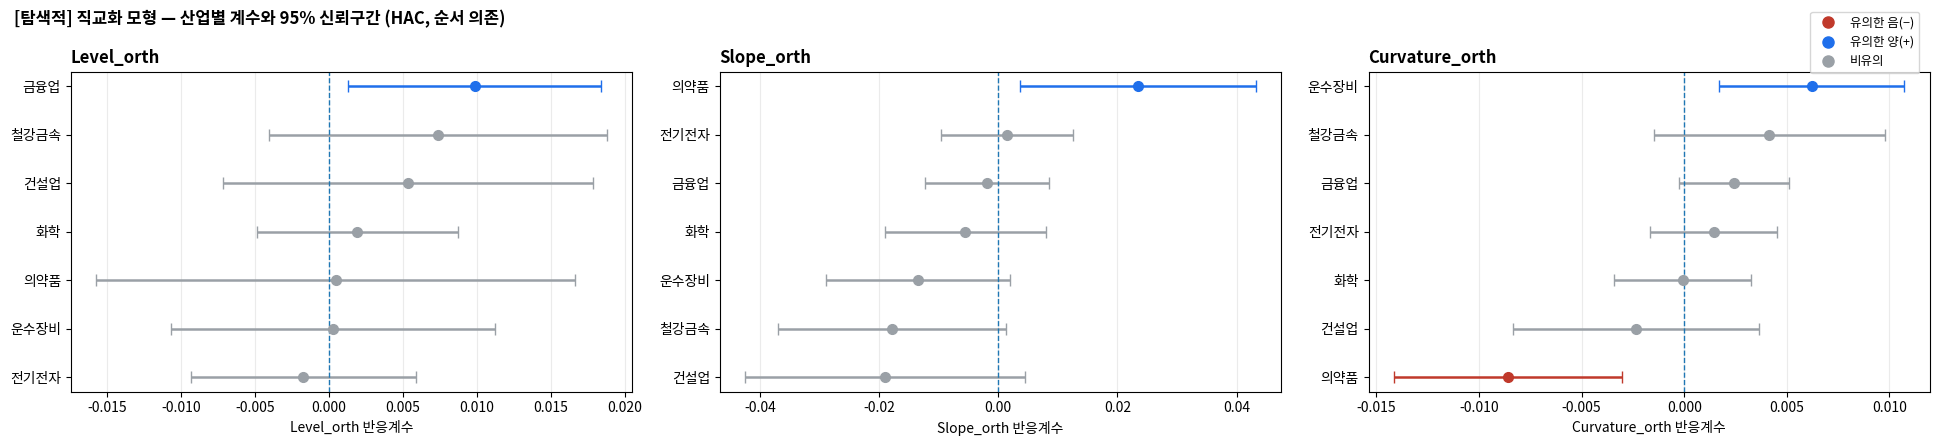

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/07_orthogonalized_ci.png


In [39]:
# 2요인·직교화 모형의 계수 신뢰구간 그림 (12단계 errorbar 스타일 유지)
def plot_factor_ci(result, factors, title, out_path, ncols=2):
    """요인별 산업 계수와 95% CI 를 패널로 그린다. 스타일은 12단계와 동일.

    부호 색상 규칙(STYLE_GUIDE §12): 유의 판정은 p_value < 0.05(significant_5pct) 기준.
    """
    nrows = int(np.ceil(len(factors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.5 * nrows),
                             squeeze=False)
    flat = axes.ravel()

    for ax, factor in zip(flat, factors):
        d = (result[result["factor"] == factor]
             .sort_values("coefficient")
             .reset_index(drop=True))
        y_pos = np.arange(len(d))

        point_colors = [
            config.sign_color(coef, sig)
            for coef, sig in zip(d["coefficient"], d["significant_5pct"])
        ]

        for y, coef, lo, hi, color in zip(
            y_pos,
            d["coefficient"],
            d["coefficient"] - d["ci_lower_95"],
            d["ci_upper_95"] - d["coefficient"],
            point_colors,
        ):
            ax.errorbar(
                coef, y,
                xerr=[[lo], [hi]],
                fmt="o", capsize=4, linewidth=1.8, markersize=7,
                color=color, ecolor=color,
            )
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(d["industry"])
        ax.set_xlabel(f"{factor} 반응계수")
        ax.set_title(factor, loc="left", fontweight="bold")
        ax.grid(axis="x", alpha=0.25)

    for ax in flat[len(factors):]:
        ax.set_visible(False)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["neg"], label="유의한 음(\u2212)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["pos"], label="유의한 양(+)"),
        Line2D([0], [0], marker="o", linestyle="None", markersize=8,
               color=config.SIGN_COLORS["ns"], label="비유의"),
    ]
    fig.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=9,
               bbox_to_anchor=(0.99, 0.99))

    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("그림 저장:", out_path)


plot_factor_ci(
    two_factor_betas, ["Level", "Slope"],
    "[탐색적] 2요인 모형 — 산업별 계수와 95% 신뢰구간 (HAC)",
    config.H1_FIGDIR / "06_two_factor_ci.png",
)

plot_factor_ci(
    orthogonalized_betas, ["Level_orth", "Slope_orth", "Curvature_orth"],
    "[탐색적] 직교화 모형 — 산업별 계수와 95% 신뢰구간 (HAC, 순서 의존)",
    config.H1_FIGDIR / "07_orthogonalized_ci.png",
    ncols=3,
)


In [40]:
# 모형별 유의 조합 수 비교
comparison = pd.DataFrame([
    {"모형": "3요인 (B-1 기준)",
     "설명변수": 3,
     "유의_조합": int(yield_curve_factor_betas["significant_5pct"].sum()),
     "전체_조합": len(yield_curve_factor_betas),
     "최대_VIF": round(max(v for k, v in vif_values.items() if k != "d_credit_spread"), 2)},
    {"모형": "4요인 (B-2 확장)",
     "설명변수": 4,
     "유의_조합": int(credit_spread_extended["significant_5pct"].sum()),
     "전체_조합": len(credit_spread_extended),
     "최대_VIF": round(max(vif_values.values()), 2)},
    {"모형": "2요인 (탐색적)",
     "설명변수": 2,
     "유의_조합": int(two_factor_betas["significant_5pct"].sum()),
     "전체_조합": len(two_factor_betas),
     "최대_VIF": round(max(two_factor_vif.values()), 2)},
    {"모형": "직교화 3요인 (탐색적)",
     "설명변수": 3,
     "유의_조합": int(orthogonalized_betas["significant_5pct"].sum()),
     "전체_조합": len(orthogonalized_betas),
     "최대_VIF": 1.0},
])

print("동시검정(F) 유의 산업:", int(joint_ftest["joint_sig_5pct"].sum()), "/ 7")
print()
display(comparison)
print()
print("주의: 유의 개수가 많은 모형이 더 옳은 모형이 아니다.")
print("      모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking 이다.")


동시검정(F) 유의 산업: 3 / 7



,모형,설명변수,유의_조합,전체_조합,최대_VIF
0,3요인 (B-1 기준),3,3,21,7.25
1,4요인 (B-2 확장),4,3,28,7.25
2,2요인 (탐색적),2,1,14,3.45
3,직교화 3요인 (탐색적),3,4,21,1.00



주의: 유의 개수가 많은 모형이 더 옳은 모형이 아니다.
      모형을 바꿔가며 유의한 결과를 고르는 것은 p-hacking 이다.


## D-6. HAC 시차 민감도

### 왜 확인하나

지금까지 모든 회귀는 `maxlags=5`를 썼다. Baseline·B-1과 맞추려고 고정한 값이다.

그런데 Newey–West 경험식은 다른 값을 제시한다.

$$
\text{maxlags} = 4\left(\frac{T}{100}\right)^{2/9}
$$

T=2,451이면 **약 8**이다. 지금 쓰는 5보다 크다.

시차를 늘리면 표준오차가 커지는 게 보통이라 p값도 올라간다. 즉 지금 결과가 **시차를 짧게 잡아서 나온 것은 아닌지** 확인해야 한다.

### 무엇을 보나

시차를 5·8·10·20으로 바꿔가며 세 가지를 다시 본다.

1. 3요인 모형 개별 계수 — 유의했던 의약품·운수장비 Curvature가 버티는가
2. 4요인 모형 Credit Spread — 계속 비유의인가
3. 동시검정(D-1) — 같은 두 산업이 버티는가

**산업 간 차이 검정(D-4)은 날짜 클러스터 표준오차를 쓰므로 HAC 시차와 무관하다.** 여기서 다루지 않는다.

### 판단 기준

계수는 시차와 무관하게 똑같다. HAC는 표준오차만 바꾼다.
따라서 **유의성 판정이 뒤집히는 조합이 몇 개인지**만 보면 된다.


In [41]:
# Newey-West 경험식으로 권장 시차를 계산해 둔다(보고서에 근거로 쓴다).
N_OBS_PER_INDUSTRY = int(
    extended_panel.dropna(
        subset=["industry_return", "kospi_return", "d_ns_level"]
    ).groupby("industry").size().iloc[0]
)

RULE_OF_THUMB_LAGS = 4 * (N_OBS_PER_INDUSTRY / 100) ** (2 / 9)

HAC_LAG_GRID = [5, 8, 10, 20]

print(f"산업별 관측치 T = {N_OBS_PER_INDUSTRY}")
print(f"Newey-West 경험식 4(T/100)^(2/9) = {RULE_OF_THUMB_LAGS:.2f}  →  약 {round(RULE_OF_THUMB_LAGS)}")
print(f"현재 사용값 = {HAC_LAGS}")
print(f"검토할 시차 = {HAC_LAG_GRID}")


산업별 관측치 T = 2451
Newey-West 경험식 4(T/100)^(2/9) = 8.14  →  약 8
현재 사용값 = 5
검토할 시차 = [5, 8, 10, 20]


In [42]:
def run_hac_sensitivity(data, lag_grid, x_cols, factor_labels, model_name):
    """HAC 시차를 바꿔가며 같은 모형을 다시 추정한다."""
    frames = []

    for lags in lag_grid:
        r = run_yield_curve_factor_model(
            data, hac_lags=lags, x_cols=x_cols, factor_labels=factor_labels,
        )
        r["model"] = model_name
        frames.append(r)

    return pd.concat(frames, ignore_index=True)


# (1) 3요인 모형
sens_three = run_hac_sensitivity(
    extended_panel, HAC_LAG_GRID,
    x_cols=["kospi_return", "d_ns_level", "d_ns_slope", "d_ns_curvature"],
    factor_labels={"d_ns_level": "Level", "d_ns_slope": "Slope",
                   "d_ns_curvature": "Curvature"},
    model_name="B_ThreeFactor",
)

# (2) 4요인 모형 (Credit Spread 포함)
sens_four = run_hac_sensitivity(
    extended_panel, HAC_LAG_GRID,
    x_cols=CREDIT_X_COLS,
    factor_labels=CREDIT_FACTOR_LABELS,
    model_name="C_FourFactor",
)

hac_sensitivity = pd.concat([sens_three, sens_four], ignore_index=True)

# 계수가 시차에 따라 변하지 않는지 확인한다(변하면 구현이 잘못된 것이다).
_coef_spread = (
    hac_sensitivity
    .groupby(["model", "industry", "factor"])["coefficient"]
    .agg(lambda s: s.max() - s.min())
    .max()
)
print(f"[검증] 시차별 계수 최대 변동폭: {_coef_spread:.3e}  (0이어야 정상)")
if _coef_spread > 1e-12:
    raise RuntimeError("HAC 시차가 계수를 바꿨습니다. 구현을 확인하세요.")

sens_path = config.H1_TABDIR / "exploratory_hac_sensitivity.csv"
hac_sensitivity.to_csv(sens_path, index=False, encoding="utf-8-sig")
print("저장 완료:", sens_path)

# 유의성 판정이 시차에 따라 바뀌는 조합을 찾는다.
flip = (
    hac_sensitivity
    .groupby(["model", "industry", "factor"])["significant_5pct"]
    .nunique()
    .reset_index(name="n_distinct")
)
flipped = flip[flip["n_distinct"] > 1]

print()
print(f"검토한 조합: {len(flip)}개  (모형 2개 x 산업 7개 x 요인)")
print(f"시차에 따라 유의성이 뒤집힌 조합: {len(flipped)}개")
if len(flipped):
    display(
        hac_sensitivity.merge(flipped[["model", "industry", "factor"]],
                              on=["model", "industry", "factor"])
        [["model", "industry", "factor", "hac_lags", "coefficient",
          "std_error_hac", "p_value", "significant_5pct"]]
        .round(6)
    )


[검증] 시차별 계수 최대 변동폭: 0.000e+00  (0이어야 정상)
저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/exploratory_hac_sensitivity.csv

검토한 조합: 49개  (모형 2개 x 산업 7개 x 요인)
시차에 따라 유의성이 뒤집힌 조합: 0개


In [43]:
# 동시검정(D-1)도 시차를 바꿔 다시 본다.
joint_sensitivity = pd.concat(
    [
        run_joint_significance_test(extended_panel, hac_lags=lags)
        .assign(hac_lags=lags)
        for lags in HAC_LAG_GRID
    ],
    ignore_index=True,
)

joint_pivot = joint_sensitivity.pivot(
    index="industry", columns="hac_lags", values="joint_p_value"
).sort_values(HAC_LAG_GRID[0])

print("동시검정 p값 — 시차별")
display(joint_pivot.round(5))

joint_flip = (
    joint_sensitivity.groupby("industry")["joint_sig_5pct"].nunique()
)
print("시차에 따라 판정이 뒤집힌 산업:",
      list(joint_flip[joint_flip > 1].index) or "없음")


동시검정 p값 — 시차별


hac_lags,5,8,10,20
industry,,,,
의약품,0.00268,0.00384,0.00505,0.01012
운수장비,0.01313,0.01248,0.01163,0.00751
금융업,0.03057,0.03733,0.04208,0.05150
철강금속,0.10744,0.10309,0.10841,0.12462
건설업,0.28955,0.30858,0.32004,0.32183
전기전자,0.76133,0.75921,0.76799,0.78449
화학,0.79026,0.78210,0.77697,0.77645


시차에 따라 판정이 뒤집힌 산업: ['금융업']


### 그림 읽는 법

왼쪽은 3요인 모형에서 산업별 **가장 작은 개별 p값**, 오른쪽은 **동시검정 p값**이다.
가로축은 HAC 시차, 세로축은 p값(로그축)이다.
회색 점선이 경험식 권장값, 붉은 선이 p=0.05다.

선이 붉은 선을 넘나들면 시차 선택에 따라 판정이 바뀐다는 뜻이다.


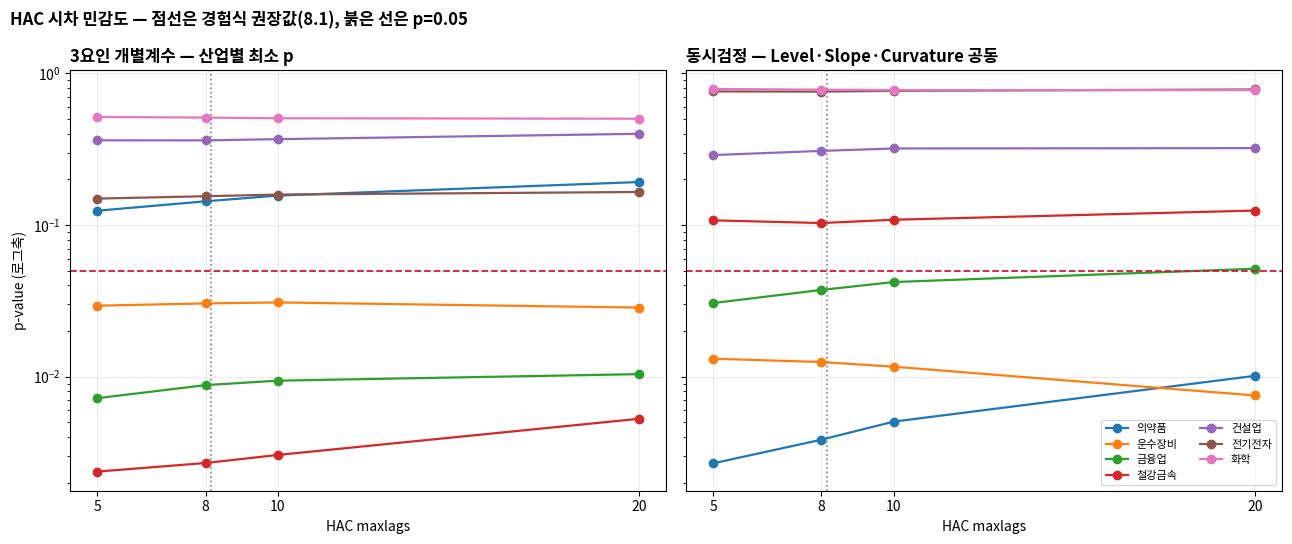

그림 저장: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/figures/10_hac_sensitivity.png


In [44]:
min_individual = (
    hac_sensitivity[hac_sensitivity["model"] == "B_ThreeFactor"]
    .groupby(["industry", "hac_lags"])["p_value"].min()
    .unstack("hac_lags")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for ax, table, title in [
    (axes[0], min_individual, "3요인 개별계수 — 산업별 최소 p"),
    (axes[1], joint_pivot, "동시검정 — Level·Slope·Curvature 공동"),
]:
    for industry in table.index:
        ax.plot(table.columns, table.loc[industry], marker="o",
                linewidth=1.6, label=industry)

    ax.axhline(0.05, linestyle="--", linewidth=1.3, color="crimson")
    ax.set_xticks(HAC_LAG_GRID)
    ax.set_xlabel("HAC maxlags")
    ax.set_yscale("log")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("p-value (로그축)")
axes[0].axvline(RULE_OF_THUMB_LAGS, linestyle=":", linewidth=1.2, color="gray")
axes[1].axvline(RULE_OF_THUMB_LAGS, linestyle=":", linewidth=1.2, color="gray")
axes[1].legend(fontsize=8, ncol=2)

fig.suptitle(
    f"HAC 시차 민감도 — 점선은 경험식 권장값({RULE_OF_THUMB_LAGS:.1f}), "
    "붉은 선은 p=0.05",
    x=0.01, ha="left", fontweight="bold",
)
fig.tight_layout()

sens_fig_path = config.H1_FIGDIR / "10_hac_sensitivity.png"
fig.savefig(sens_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("그림 저장:", sens_fig_path)


# PART E. 후속 검토

본분석에서 남은 두 질문을 확인한다.

1. **곡률과 신용스프레드의 중첩은 어떤 성격인가** — Credit Spread를 넣으면 곡률 계수가 줄어든다.
   이것이 실제 효과 감소인가, 아니면 겹친 부분을 어느 쪽에 배정하느냐의 문제인가.
2. **의약품·운수장비의 부호 차이를 경제적으로 설명할 수 있는가** — 방어주와 경기민감주의
   차이로 볼 수 있는지 확인한다.

## E-1. 곡률–신용스프레드 중첩의 성격

### 왜 확인하나

4요인 모형에서 곡률 계수가 **13~36%** 줄고 **BH p가 0.0901**로 밀렸다.
두 가지 해석이 가능하다.

- **(a) 실제 효과 감소** — 곡률로 보이던 것의 일부가 사실 신용위험 효과였다
- **(b) 배정 문제** — 두 변수가 겹치는 부분을 신용스프레드가 가져갔을 뿐이다

### 어떻게 구분하나

신용스프레드를 **곡선 3요인에 직교화**한 뒤 다시 넣는다.
그러면 신용스프레드는 곡선요인과 겹치지 않는 **고유 성분만** 갖는다.

FWL 정리에 의해, 이때 곡률 계수가 **3요인 모형과 같아지면 (b)**,
여전히 줄어들면 **(a)** 다.

In [45]:
# 신용스프레드 중 곡선요인으로 설명되는 부분이 얼마나 되는가
factor_daily_e = (
    extended_panel[["date", "d_ns_level", "d_ns_slope", "d_ns_curvature",
                    "d_credit_spread"]]
    .drop_duplicates(subset="date").dropna().reset_index(drop=True)
)
_X = sm.add_constant(factor_daily_e[["d_ns_level", "d_ns_slope", "d_ns_curvature"]],
                     has_constant="add")
_m = sm.OLS(factor_daily_e["d_credit_spread"], _X).fit()

print(f"신용스프레드를 곡선 3요인에 회귀 → R² = {_m.rsquared:.4f}")
print(f"  겹치는 부분 {_m.rsquared*100:.1f}%, 고유 부분 {(1-_m.rsquared)*100:.1f}%")
print(f"  곡률 계수 {_m.params['d_ns_curvature']:+.4f} (t = {_m.tvalues['d_ns_curvature']:.2f})")

# 곡선요인과 겹치지 않는 신용스프레드(직교화)
factor_daily_e["d_credit_orth"] = _m.resid
exploratory_panel_e = extended_panel.merge(
    factor_daily_e[["date", "d_credit_orth"]], on="date", how="left")


신용스프레드를 곡선 3요인에 회귀 → R² = 0.1859
  겹치는 부분 18.6%, 고유 부분 81.4%
  곡률 계수 -0.0299 (t = -18.36)


In [46]:
CREDIT_ORTH_X = ["kospi_return", "d_ns_level", "d_ns_slope",
                 "d_ns_curvature", "d_credit_orth"]
CREDIT_ORTH_LABELS = {"d_ns_level": "Level", "d_ns_slope": "Slope",
                      "d_ns_curvature": "Curvature", "d_credit_orth": "CreditSpread_orth"}

credit_orth_betas = (
    run_yield_curve_factor_model(exploratory_panel_e, hac_lags=HAC_LAGS,
                                 x_cols=CREDIT_ORTH_X,
                                 factor_labels=CREDIT_ORTH_LABELS)
    .assign(model="E_CreditOrthogonalized")
    .pipe(add_bh_correction, group_cols=("model", "factor"))
)

# 세 모형의 Curvature 계수를 나란히 비교
overlap_check = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "coefficient", "std_error_hac"]]
    .rename(columns={"coefficient": "coef_3factor", "std_error_hac": "se_3factor"})
    .merge(credit_spread_betas[
               (credit_spread_betas["model"] == "B_Extended_4Factor") &
               (credit_spread_betas["factor"] == "Curvature")]
           [["industry", "coefficient", "p_value_bh"]]
           .rename(columns={"coefficient": "coef_4factor", "p_value_bh": "bh_4factor"}),
           on="industry")
    .merge(credit_orth_betas[credit_orth_betas["factor"] == "Curvature"]
           [["industry", "coefficient", "p_value_bh"]]
           .rename(columns={"coefficient": "coef_orth", "p_value_bh": "bh_orth"}),
           on="industry")
)
overlap_check["차이_3요인vs직교화"] = (
    overlap_check["coef_3factor"] - overlap_check["coef_orth"]).abs()

overlap_path = config.H1_TABDIR / "credit_curvature_overlap.csv"
overlap_check.to_csv(overlap_path, index=False, encoding="utf-8-sig")

display(overlap_check.round(6))
print()
print(f"3요인 vs 직교화 4요인 계수 최대 차이: "
      f"{overlap_check['차이_3요인vs직교화'].max():.2e}")
print("→ 0에 가까우면 '약해짐'은 실제 효과 감소가 아니라 공유분 재배정이다.")
print()
print("저장 완료:", overlap_path)


,industry,coef_3factor,se_3factor,coef_4factor,bh_4factor,coef_orth,bh_orth,차이_3요인vs직교화
0,건설업,-0.002338,0.003058,-0.002313,0.572208,-0.002337,0.518830,0.000000
1,금융업,0.002413,0.001370,0.001543,0.524882,0.002412,0.180179,0.000001
2,운수장비,0.006207,0.002310,0.005363,0.090107,0.006206,0.023980,0.000001
3,의약품,-0.008599,0.002828,-0.006435,0.090107,-0.008596,0.016151,0.000003
4,전기전자,0.001441,0.001582,0.001537,0.524882,0.001441,0.505779,0.000000
5,철강금속,0.004148,0.002878,0.002900,0.524882,0.004146,0.250641,0.000002
6,화학,-0.000080,0.001704,0.000758,0.688090,-0.000079,0.963535,0.000001



3요인 vs 직교화 4요인 계수 최대 차이: 2.90e-06
→ 0에 가까우면 '약해짐'은 실제 효과 감소가 아니라 공유분 재배정이다.

저장 완료: /sessions/relaxed-awesome-shannon/mnt/FINDSLAB-Research-Intern/results/H1_yield_curve/tables/credit_curvature_overlap.csv


## E-2. 부호 차이의 경제적 해석 시도

### 무엇을 확인하나

의약품(−)과 운수장비(+)의 부호가 반대다.
**방어주와 경기민감주의 차이**로 볼 수 있다면, 곡률 노출이 경기민감도와 관련되어야 한다.

경기민감도의 대용치로 **시장베타(KOSPI 계수)** 를 쓴다.
산업이 7개뿐이므로 순위상관(Spearman)으로만 본다. 계획서의 H3 방식과 같다.

### 판단 기준

- 상관이 뚜렷하게 양(+)이면 → "경기민감할수록 곡률 노출이 양(+)" 해석과 정합적
- 상관이 없으면 → **이 해석을 쓰면 안 된다**

In [47]:
from scipy.stats import spearmanr

beta_profile = (
    yield_curve_factor_betas[yield_curve_factor_betas["factor"] == "Curvature"]
    [["industry", "market_beta", "coefficient", "p_value"]]
    .rename(columns={"coefficient": "curvature_beta", "p_value": "curvature_p"})
    .sort_values("market_beta").reset_index(drop=True)
)

rho, pval = spearmanr(beta_profile["market_beta"], beta_profile["curvature_beta"])
beta_profile["spearman_rho"] = round(rho, 4)
beta_profile["spearman_p"] = round(pval, 4)

profile_path = config.H1_TABDIR / "curvature_market_beta_profile.csv"
beta_profile.to_csv(profile_path, index=False, encoding="utf-8-sig")

display(beta_profile.round(5))
print(f"\n시장베타 vs 곡률계수  Spearman rho = {rho:+.3f}  (p = {pval:.4f}, n=7)")
print()
if pval < 0.10:
    print("→ 경기민감도와 곡률 노출 사이에 관련이 있다.")
else:
    print("→ 관련이 확인되지 않는다.")
    print("   '방어주 대 경기민감주' 해석은 이 자료로 뒷받침되지 않는다.")
    print("   부호 차이는 관찰 사실로만 보고하고 해석을 붙이지 않는다.")


,industry,market_beta,curvature_beta,curvature_p,spearman_rho,spearman_p
0,의약품,0.78917,-0.00860,0.00236,0.1429,0.7599
1,금융업,0.92575,0.00241,0.07807,0.1429,0.7599
2,운수장비,1.00631,0.00621,0.00721,0.1429,0.7599
3,건설업,1.01328,-0.00234,0.44457,0.1429,0.7599
4,철강금속,1.02485,0.00415,0.14948,0.1429,0.7599
5,화학,1.05406,-0.00008,0.96244,0.1429,0.7599
6,전기전자,1.20647,0.00144,0.36228,0.1429,0.7599



시장베타 vs 곡률계수  Spearman rho = +0.143  (p = 0.7599, n=7)

→ 관련이 확인되지 않는다.
   '방어주 대 경기민감주' 해석은 이 자료로 뒷받침되지 않는다.
   부호 차이는 관찰 사실로만 보고하고 해석을 붙이지 않는다.


---

# 부록. 만기 확대 검토

국고채 20년·30년을 추가해 만기를 6개로 늘렸을 때의 결과다.
**본분석에는 반영하지 않는다.** 확인 결과 요인 분리가 개선되지 않았기 때문이다.

| 만기 세트 | 곡선 RMSE | 최대 VIF |
|---|---|---|
| 1·3·5·10년 (본분석) | 0.01084 | 9.46 |
| + 20·30년 | 0.03837 (3.5배) | **18.36** |

만기를 늘리자 Nelson–Siegel 3요인이 넓어진 만기 범위를 따라가지 못해
곡선 적합도가 나빠지고, 요인 중첩은 오히려 심해졌다.

또한 **국고채 2년물은 2021-03-10부터만 존재**해 전체 표본 분석에 쓸 수 없다.
2년물을 포함하면 표본이 2,451일에서 1,186일로 줄어든다.

> 상세 결과는 `notebooks/06-1_treasury_yield_curve.ipynb` 와
> `docs/private/maturity_extension/` 에 있다.
> 만기 개수는 요인 중첩의 원인이 아니다.